# Task 2d: Delta / Spindle Coupling, All 16 Rats

Delta-spindle coupling on all 16 rats (ripples aren't used, so no 7-rat restriction). Plots only, the surrogate is in the 7-rat notebook.

### Pairings

All nine delta-area x spindle-area pairs (PL/RSC/HPC x PL/RSC/HPC), Yixiao Oct 2026.

### Window

Delta -> Spindle, 100-1300 ms peak-to-peak (`PROJECT_DATA_REFERENCE.md`).

`lag = spindle_peak - delta_peak`, positive = spindle after delta.

PL-PL, RSC-RSC and HPC-HPC use the same electrode for both waves (possible leakage), the six cross-area pairs don't.

---
# Load and restrict

## Configuration

In [6]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# lab repo root on the path, so `modules` imports work from this folder
REPO_ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "modules" / "project_config.py").exists()
)
sys.path.insert(0, str(REPO_ROOT))
from modules.project_config import get_path  # noqa: E402

# local paths come from config.yaml (see config.example.yaml)
ROOT = get_path("R1_8_root")  # holds Rat_HM_Ephys_TD_Analysis_R1_8 and _R9_16
assert get_path("R9_16_root") == ROOT, "these notebooks expect R1_8_root == R9_16_root"
WAVE_CACHE = get_path("event_cache_root")
SESSION_MAP_CSV = get_path("session_map_csv")
DAY_GRID_XLSX = get_path("day_grid_xlsx")
OUT = REPO_ROOT / "results" / "leticia_event_coupling"  # figures and caches
SPINDLE_METHOD = "wavelet_amp_1_ampcore_3"
PHASES = ["postsleep"]

BOUT_KEYS = ["rat", "date", "trial", "nrem_bout_index"]

# all nine pairings (Yixiao, Oct 2026)
AREAS = ["PL", "RSC", "HPC"]
PAIRS = [(d, s) for d in AREAS for s in AREAS]

WINDOW_MS = (100, 1300)  # Delta -> Spindle, peak-to-peak (PROJECT_DATA_REFERENCE.md)

# all 16 rats (no ripples used)
RATS = list(range(1, 17))

FIGDIR = OUT / "task2d_16rats_figures"
FIGDIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Save a figure. Takes the figure object explicitly -- plt.gcf() is
    unreliable after tight_layout() and returns a blank figure after show()."""
    fig.savefig(FIGDIR / f"{name}.png", dpi=200, bbox_inches="tight")
    print("saved:", name)


print("drive reachable:", ROOT.exists())
print("rats in analysis:", RATS)
print("pairs:", PAIRS, "| window:", WINDOW_MS)

drive reachable: True
rats in analysis: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
pairs: [('PL', 'PL'), ('PL', 'RSC'), ('PL', 'HPC'), ('RSC', 'PL'), ('RSC', 'RSC'), ('RSC', 'HPC'), ('HPC', 'PL'), ('HPC', 'RSC'), ('HPC', 'HPC')] | window: (100, 1300)


## Load and restrict

Loads from the event cache (`event_cache_root` in `config.yaml`); `add_condition` adds HC / Training.

In [7]:
from modules.event_coupling.build_tables import add_condition, build_wave

deltas = add_condition(
    build_wave(ROOT, "delta", SPINDLE_METHOD, PHASES, WAVE_CACHE, rebuild=False),
    SESSION_MAP_CSV,
)
spindles = add_condition(
    build_wave(ROOT, "spindle", SPINDLE_METHOD, PHASES, WAVE_CACHE, rebuild=False),
    SESSION_MAP_CSV,
)

print(f"all 16 rats : {len(deltas):>10,} deltas | {len(spindles):>10,} spindles")

# all 16 rats, drop Maze_Hab / Novelty / aborted days
dlt = deltas[(deltas["rat"].isin(RATS)) & (deltas["group"] != "other")]
spn = spindles[
    (spindles["rat"].isin(RATS))
    & (spindles["group"] != "other")
    & (spindles["area"].isin(["PL", "RSC", "HPC"]))
]

print(f"all 16 rats : {len(dlt):>10,} deltas | {len(spn):>10,} spindles")
print(
    f"             ({100 * len(dlt) / len(deltas):.0f}% of deltas, "
    f"{100 * len(spn) / len(spindles):.0f}% of spindles)"
)
print(dlt.groupby("group").size().to_string())

delta: 48 units to gather


KeyboardInterrupt: 

## Goal locations, session types and HC context

- `gl_num` / `session_num` from the StudyDay workbooks (`gl_sessions.py`)
- `session_type`: S1 = new goal location, S2/S4 = probe, S3/S5 = normal
- HC context: goal location before, next session, retention delay

In [3]:
from modules.event_coupling.gl_sessions import add_gl_sessions, build_gl_sessions
from modules.event_coupling.hc_sessions import (
    add_session_type,
    attach_hc_context,
    build_day_table,
)


def prep_keys(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"]).dt.normalize()
    df["rat"] = df["rat"].astype("int64")
    return df


gl = prep_keys(build_gl_sessions(ROOT, cache_dir=WAVE_CACHE, rebuild=False))
days = add_session_type(build_day_table(DAY_GRID_XLSX, verbose=False))
hc_ctx = attach_hc_context(days, gl_table=gl, verbose=False)

SESSION_COLS = ["rat", "date", "session_type"]
HC_COLS = [
    "rat",
    "date",
    "hc_phase",
    "follows_gl",
    "next_type",
    "retention_delay",
    "is_consolidation",
]


def add_context(df):
    df = add_gl_sessions(prep_keys(df), gl)
    df = df.merge(
        prep_keys(days)[SESSION_COLS].drop_duplicates(), on=["rat", "date"], how="left"
    )
    df = df.merge(
        prep_keys(hc_ctx)[HC_COLS].drop_duplicates(), on=["rat", "date"], how="left"
    )
    return df


dlt_ctx = add_context(dlt)
spn_ctx = add_context(spn)

print(dlt_ctx.groupby(["group", "session_type"], dropna=False).size().to_string())

group     session_type
HC        NaN             3302771
Training  NGL             1496131
          normal          1854391
          probe           2159422


### Enough data in each group?

With few rats per cell a sign-flip test can't reach p < 0.05 below n = 4.

In [4]:
def cell_rats(df, keys, label):
    d = df.dropna(subset=[k for k in keys if k != "group"])
    g = (
        d.groupby(keys, dropna=False, observed=True)
        .agg(rats=("rat", "nunique"), bouts=("nrem_bout_index", "size"))
        .reset_index()
    )
    g["n_ok"] = np.where(
        g["rats"] >= 6, "yes", np.where(g["rats"] >= 4, "marginal", "NO")
    )
    print(f"--- {label} ---")
    print(g.to_string(index=False))
    print()


cell_rats(
    dlt_ctx[dlt_ctx["group"] == "HC"], ["retention_delay"], "HC by retention delay"
)
cell_rats(
    dlt_ctx[dlt_ctx["group"] == "Training"],
    ["session_type"],
    "Training by session type",
)
cell_rats(dlt_ctx, ["cohort", "group"], "cohort x group")

--- HC by retention delay ---
retention_delay  rats  bouts n_ok
            48h    13 490962  yes
             7d    16 871115  yes

--- Training by session type ---
session_type  rats   bouts n_ok
         NGL    16 1496131  yes
      normal    16 1854391  yes
       probe    16 2159422  yes

--- cohort x group ---
  cohort    group  rats   bouts n_ok
 rats1-8       HC     8 1283264  yes
 rats1-8 Training     8 2154557  yes
rats9-16       HC     8 2019507  yes
rats9-16 Training     8 3355387  yes



---
# Fixed-window count

Per pair, since spindles have their own area.

## Fixed-window count

Spindle peak 100-1300 ms after a delta peak.

In [5]:
from modules.event_coupling.coupling import count_sequences

ds = {}
for d_area, s_area in PAIRS:
    pair_label = f"{d_area} delta - {s_area} spindle"
    r = count_sequences(
        dlt[dlt["area"] == d_area],
        spn,
        "delta",
        "spindle",
        window_ms=WINDOW_MS,
        second_area=s_area,
    )
    ds[(d_area, s_area)] = r
    print(
        f"{pair_label:<22}: bouts {len(r):>7,} | total D->S sequences "
        f"{r['n_sequences'].sum():>9,} | spindles in those bouts "
        f"{r['n_spindle'].sum():>9,}"
    )

PL delta - PL spindle : bouts  25,333 | total D->S sequences   144,540 | spindles in those bouts   109,410
PL delta - RSC spindle: bouts  25,333 | total D->S sequences   184,323 | spindles in those bouts   140,463
PL delta - HPC spindle: bouts  25,333 | total D->S sequences   207,799 | spindles in those bouts   161,259
RSC delta - PL spindle: bouts  25,353 | total D->S sequences   139,715 | spindles in those bouts   109,423
RSC delta - RSC spindle: bouts  25,353 | total D->S sequences   189,015 | spindles in those bouts   140,475
RSC delta - HPC spindle: bouts  25,353 | total D->S sequences   211,755 | spindles in those bouts   161,284
HPC delta - PL spindle: bouts  24,259 | total D->S sequences   135,854 | spindles in those bouts    99,155
HPC delta - RSC spindle: bouts  24,259 | total D->S sequences   191,771 | spindles in those bouts   132,618
HPC delta - HPC spindle: bouts  24,259 | total D->S sequences   226,002 | spindles in those bouts   157,032


### Yixiao's counting rule

Each spindle counted once. `window_ms` passed directly (no delta-spindle entry in `WINDOWS_MS`).

Analytic chance `1 - exp(-r*w)` overestimates the effect (delta waves are rhythmic), the surrogate below is the real null.

In [6]:
from modules.event_coupling.coupling_unique import count_sequences_unique

for d_area, s_area in PAIRS:
    pair_label = f"{d_area} delta - {s_area} spindle"
    u = count_sequences_unique(
        dlt[dlt["area"] == d_area],
        spn[spn["area"] == s_area],
        "delta",
        "spindle",
        window_ms=WINDOW_MS,
    )
    obs, n = u["n_sequences"].sum(), u["n_spindle"].sum()
    print(
        f"{pair_label:<22}: {obs:>8,} of {n:>8,} spindles coupled ({100 * obs / n:.1f}%)"
    )

PL delta - PL spindle :   85,566 of  109,410 spindles coupled (78.2%)
PL delta - RSC spindle:  109,912 of  140,463 spindles coupled (78.2%)
PL delta - HPC spindle:  124,704 of  161,259 spindles coupled (77.3%)
RSC delta - PL spindle:   83,026 of  109,423 spindles coupled (75.9%)
RSC delta - RSC spindle:  112,178 of  140,475 spindles coupled (79.9%)
RSC delta - HPC spindle:  126,421 of  161,284 spindles coupled (78.4%)
HPC delta - PL spindle:   77,878 of   99,155 spindles coupled (78.5%)
HPC delta - RSC spindle:  108,588 of  132,618 spindles coupled (81.9%)
HPC delta - HPC spindle:  127,572 of  157,032 spindles coupled (81.2%)


## Bout durations

Bouts have to be longer than the shift used in the negative control.

In [7]:
bout_dur = dlt[BOUT_KEYS + ["nrem_bout_duration_s"]].drop_duplicates()
print(bout_dur["nrem_bout_duration_s"].describe().round(1).to_string())

count    25365.0
mean       113.5
std        115.3
min          1.0
25%         35.0
50%         74.0
75%        150.0
max       1443.0


## Negative control with a shifted window

Same 1200 ms width, starting 5000 ms after each delta.

| ratio (control / real) | meaning |
|---|---|
| well below 1 | good, we're measuring timing |
| near 1 | bad, we're measuring event density |

In [8]:
WINDOW_WIDTH_MS = WINDOW_MS[1] - WINDOW_MS[0]  # 1200 ms
CTRL_WINDOW_MS = (WINDOW_MS[0] + 5000, WINDOW_MS[1] + 5000)  # (5100, 6300)

for d_area, s_area in PAIRS:
    pair_label = f"{d_area} delta - {s_area} spindle"
    ctrl = count_sequences(
        dlt[dlt["area"] == d_area],
        spn,
        "delta",
        "spindle",
        window_ms=CTRL_WINDOW_MS,
        second_area=s_area,
    )
    real_total, ctrl_total = (
        ds[(d_area, s_area)]["n_sequences"].sum(),
        ctrl["n_sequences"].sum(),
    )
    print(
        f"{pair_label:<22}: real {real_total:>9,} | control {ctrl_total:>9,} "
        f"| ratio {ctrl_total / real_total:.3f}"
    )

PL delta - PL spindle : real   144,540 | control   133,282 | ratio 0.922
PL delta - RSC spindle: real   184,323 | control   169,100 | ratio 0.917
PL delta - HPC spindle: real   207,799 | control   188,432 | ratio 0.907
RSC delta - PL spindle: real   139,715 | control   133,710 | ratio 0.957
RSC delta - RSC spindle: real   189,015 | control   172,978 | ratio 0.915
RSC delta - HPC spindle: real   211,755 | control   192,607 | ratio 0.910
HPC delta - PL spindle: real   135,854 | control   127,269 | ratio 0.937
HPC delta - RSC spindle: real   191,771 | control   168,940 | ratio 0.881
HPC delta - HPC spindle: real   226,002 | control   191,837 | ratio 0.849


## What chance alone predicts

Pairs expected from event density alone (deltas x spindle rate x window width).

In [9]:
total_nrem_s = bout_dur["nrem_bout_duration_s"].sum()
window_width_s = WINDOW_WIDTH_MS / 1000.0

print(f"total NREM time      : {total_nrem_s:>12,.0f} s")
print(f"window width         : {window_width_s:>12.3f} s")
for d_area, s_area in PAIRS:
    pair_label = f"{d_area} delta - {s_area} spindle"
    n_delta = (dlt["area"] == d_area).sum()
    n_spn_area = (spn["area"] == s_area).sum()
    spindle_rate = n_spn_area / total_nrem_s
    expected = spindle_rate * window_width_s * n_delta
    observed = ds[(d_area, s_area)]["n_sequences"].sum()
    print(
        f"{pair_label:<22}: expected {expected:>10,.0f} | observed {observed:>10,} "
        f"| observed/expected {observed / expected:>7.3f}"
    )

total NREM time      :    2,877,870 s
window width         :        1.200 s
PL delta - PL spindle : expected    132,865 | observed    144,540 | observed/expected   1.088
PL delta - RSC spindle: expected    170,569 | observed    184,323 | observed/expected   1.081
PL delta - HPC spindle: expected    195,838 | observed    207,799 | observed/expected   1.061
RSC delta - PL spindle: expected    135,740 | observed    139,715 | observed/expected   1.029
RSC delta - RSC spindle: expected    174,260 | observed    189,015 | observed/expected   1.085
RSC delta - HPC spindle: expected    200,076 | observed    211,755 | observed/expected   1.058
HPC delta - PL spindle: expected    133,490 | observed    135,854 | observed/expected   1.018
HPC delta - RSC spindle: expected    171,372 | observed    191,771 | observed/expected   1.119
HPC delta - HPC spindle: expected    196,760 | observed    226,002 | observed/expected   1.149


---
# Lag histogram

Peri-event histograms, peak latencies, compared with a surrogate (slide 13).

Wider edges and baseline than delta-ripple (window is 100-1300 ms).

In [10]:
from modules.event_coupling import lag_histogram as lh

MAX_LAG_MS = 1600
EDGES = np.arange(-1600, 1620, 20)
BASELINE_MS = 1400  # tail = |lag| >= 1400, clear of the 100-1300 ms window
left = EDGES[:-1]

WINDOWS = [("D->S", WINDOW_MS[0], WINDOW_MS[1])]

### Check before using

Self-test with a planted lag. If it prints FAIL, stop.

In [11]:
lh.self_test(planted_lag_ms=200)

self_test: planted 200 ms, recovered 200 ms -> PASS


True

## Histogram per pair, full dataset

Per pair. Baseline from the tails (|lag| >= 1400 ms).

y = raw pair counts, so compare shape and peak position between pairs, not height.

In [12]:
res_full = {}
for d_area, s_area in PAIRS:
    pair_label = f"{d_area} delta - {s_area} spindle"
    lg = lh.collect_lags(
        dlt[dlt["area"] == d_area],
        spn[spn["area"] == s_area],
        "delta",
        "spindle",
        max_lag_ms=MAX_LAG_MS,
    )
    res_full[(d_area, s_area)] = lh.summarise(
        lg, EDGES, baseline_ms=BASELINE_MS, windows=WINDOWS, label=pair_label
    )
    del lg

for key, r in res_full.items():
    print(
        f"{key}: baseline/bin {r['baseline']:.1f} | noise floor ~{lh.noise_floor_pct(r):.1f}% of baseline"
    )

PL delta - PL spindle: pairs   373,986 | peak   -20 ms | + 50.2% above baseline | D->S 1.063x
PL delta - RSC spindle: pairs   480,540 | peak   420 ms | + 14.8% above baseline | D->S 1.035x
PL delta - HPC spindle: pairs   557,328 | peak  -360 ms | + 17.7% above baseline | D->S 1.026x
RSC delta - PL spindle: pairs   365,085 | peak  -340 ms | + 19.1% above baseline | D->S 1.046x
RSC delta - RSC spindle: pairs   493,804 | peak  -220 ms | + 32.2% above baseline | D->S 1.033x
RSC delta - HPC spindle: pairs   569,252 | peak  -160 ms | + 56.8% above baseline | D->S 1.029x
HPC delta - PL spindle: pairs   349,988 | peak   160 ms | + 15.5% above baseline | D->S 1.055x
HPC delta - RSC spindle: pairs   502,067 | peak  -220 ms | + 40.1% above baseline | D->S 1.045x
HPC delta - HPC spindle: pairs   594,989 | peak  -160 ms | + 76.7% above baseline | D->S 1.066x
('PL', 'PL'): baseline/bin 2264.7 | noise floor ~2.1% of baseline
('PL', 'RSC'): baseline/bin 2964.4 | noise floor ~1.8% of baseline
('PL', 'H

In [ ]:
for (d_area, s_area), r in res_full.items():
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(left, r["counts"], color="tab:blue", lw=1.6)
    ax.axhline(r["baseline"], color="k", lw=1, ls=":", label="baseline")
    ax.axvspan(
        WINDOW_MS[0], WINDOW_MS[1], color="tab:blue", alpha=0.10, label="D->S window"
    )
    ax.axvline(0, color="k", lw=1)
    ax.set_xlabel("spindle peak - delta peak (ms)   [positive = spindle after delta]")
    ax.set_ylabel("count")
    ax.set_title(f"{d_area} delta vs {s_area} spindle -- full dataset")
    ax.legend(fontsize=8)
    plt.tight_layout()
    save_fig(fig, f"02_histogram_full_{d_area}_{s_area}")
    plt.show()

In [25]:
import inspect

print(inspect.getsource(lh.collect_lags))

def collect_lags(first_df, second_df, first_wave, second_wave, max_lag_ms=1000):
    """Signed time differences between all event pairs within the same NREM bout.

    Returns a flat array of (second_peak - first_peak) in ms.
    Pairs are only formed within a bout, never across bouts.
    """
    fp, sp = f"{first_wave}_peak_index", f"{second_wave}_peak_index"
    return collect_lags_cols(first_df, second_df, fp, sp, max_lag_ms=max_lag_ms)



 ## short delta (<500ms)

In [17]:
# Delta duration < 500 ms
# First trough -> Second trough

dlt_short = dlt.copy()

dlt_short["delta_duration_ms"] = (
    dlt_short["delta_end_index"]
    - dlt_short["delta_start_index"]
) / 1000 * 1000

dlt_short = dlt_short[
    (dlt_short["delta_duration_ms"] > 0)
    & (dlt_short["delta_duration_ms"] < 500)
].copy()

print(f"Original Delta events: {len(dlt):,}")
print(f"Delta < 500 ms: {len(dlt_short):,}")
print(f"Remaining: {100 * len(dlt_short) / len(dlt):.1f}%")

Original Delta events: 8,812,715
Delta < 500 ms: 7,529,193
Remaining: 85.4%


In [18]:
# Delta-Spindle peak-to-peak
# Only Delta events with duration < 500 ms

res_short_delta = {}

for d_area, s_area in PAIRS:

    pair_label = (
        f"{d_area} delta (<500 ms) - {s_area} spindle"
    )

    lg = lh.collect_lags(
        dlt_short[dlt_short["area"] == d_area],
        spn[spn["area"] == s_area],
        "delta",
        "spindle",
        max_lag_ms=MAX_LAG_MS,
    )

    res_short_delta[(d_area, s_area)] = lh.summarise(
        lg,
        EDGES,
        baseline_ms=BASELINE_MS,
        windows=WINDOWS,
        label=pair_label,
    )

    del lg

# Print baseline and noise floor
for key, r in res_short_delta.items():
    print(
        f"{key}: baseline/bin {r['baseline']:.1f} "
        f"| noise floor ~{lh.noise_floor_pct(r):.1f}% of baseline"
    )

PL delta (<500 ms) - PL spindle: pairs   311,363 | peak   -20 ms | + 54.1% above baseline | D->S 1.055x
PL delta (<500 ms) - RSC spindle: pairs   395,912 | peak   360 ms | + 19.5% above baseline | D->S 1.044x
PL delta (<500 ms) - HPC spindle: pairs   459,193 | peak  -360 ms | + 21.4% above baseline | D->S 1.045x
RSC delta (<500 ms) - PL spindle: pairs   319,279 | peak  -340 ms | + 20.5% above baseline | D->S 1.040x
RSC delta (<500 ms) - RSC spindle: pairs   420,489 | peak  -220 ms | + 25.6% above baseline | D->S 1.033x
RSC delta (<500 ms) - HPC spindle: pairs   485,278 | peak  -160 ms | + 46.3% above baseline | D->S 1.033x
HPC delta (<500 ms) - PL spindle: pairs   304,914 | peak   160 ms | + 19.7% above baseline | D->S 1.051x
HPC delta (<500 ms) - RSC spindle: pairs   435,749 | peak  -180 ms | + 33.9% above baseline | D->S 1.050x
HPC delta (<500 ms) - HPC spindle: pairs   517,307 | peak  -160 ms | + 75.5% above baseline | D->S 1.074x
('PL', 'PL'): baseline/bin 1883.7 | noise floor ~2.3

In [ ]:
for (d_area, s_area), r in res_short_delta.items():

    fig, ax = plt.subplots(figsize=(7, 4.5))

    ax.plot(
        left,
        r["counts"],
        color="tab:blue",
        lw=1.6
    )

    ax.axhline(
        r["baseline"],
        color="k",
        lw=1,
        ls=":",
        label="baseline"
    )

    ax.axvspan(
        WINDOW_MS[0],
        WINDOW_MS[1],
        color="tab:blue",
        alpha=0.10,
        label="D->S window"
    )

    ax.axvline(0, color="k", lw=1)

    ax.set_xlabel(
        "spindle peak - delta peak (ms) "
        "[positive = spindle after delta]"
    )

    ax.set_ylabel("count")

    ax.set_title(
        f"{d_area} delta vs {s_area} spindle\n"
        "Delta duration < 500 ms"
    )

    ax.legend(fontsize=8)

    plt.tight_layout()

    save_fig(
        fig,
        f"02_histogram_delta_under500ms_{d_area}_{s_area}"
    )

    plt.show()

In [37]:
import inspect

print("=== Delta columns ===")
print(dlt_short.columns.tolist())

print("\n=== Spindle columns ===")
print(spn.columns.tolist())

print("\n=== collect_lags_cols source ===")
print(inspect.getsource(lh.collect_lags_cols))

=== Delta columns ===
['delta_start_index', 'delta_peak_index', 'delta_end_index', 'delta_duration_s', 'delta_negative_amplitude', 'delta_positive_amplitude', 'delta_peak_to_peak_amplitude', 'delta_rising_slope', 'delta_decreasing_slope', 'delta_area_under_curve', 'nrem_bout_index', 'nrem_bout_duration_s', 'nrem_bout_start_index', 'nrem_bout_end_index', 'rat', 'area', 'date', 'phase', 'channel', 'trial', 'wave', 'cohort', 'condition', 'group', 'delta_duration_ms']

=== Spindle columns ===
['spindle_start_index', 'spindle_peak_index', 'spindle_end_index', 'spindle_duration_s', 'spindle_amplitude', 'spindle_peak_frequency_hz', 'spindle_mean_frequency_hz', 'nrem_bout_index', 'nrem_bout_duration_s', 'nrem_bout_start_index', 'nrem_bout_end_index', 'rat', 'area', 'date', 'phase', 'channel', 'trial', 'wave', 'cohort', 'condition', 'group']

=== collect_lags_cols source ===
def collect_lags_cols(first_df, second_df, first_col, second_col, max_lag_ms=1000):
    """Same as collect_lags, with the

In [41]:
# wider range and baseline than the peak-to-peak histograms
MAX_LAG_MS_ES = 1600
EDGES_ES = np.arange(-1600, 1620, 20)
BASELINE_ES = 1400
left_es = EDGES_ES[:-1]

res_end_start_ds = {}
for d_area, s_area in PAIRS:
    pair_label = f"{d_area} delta - {s_area} spindle"
    lg = lh.collect_lags_cols(
        dlt[dlt["area"] == d_area],
        spn[spn["area"] == s_area],
        "delta_end_index",
        "spindle_start_index",
        max_lag_ms=MAX_LAG_MS_ES,
    )
    res_end_start_ds[(d_area, s_area)] = lh.summarise(
        lg,
        EDGES_ES,
        baseline_ms=BASELINE_ES,
        windows=[
            ("overlap (lag<0)", -MAX_LAG_MS_ES, 0),
            ("sequential (lag>=0)", 0, MAX_LAG_MS_ES),
        ],
        label=f"{pair_label} end-start",
    )

for (d_area, s_area), r in res_end_start_ds.items():
    ov = r["windows"]["overlap (lag<0)"]["observed"]
    sq = r["windows"]["sequential (lag>=0)"]["observed"]
    print(
        f"{d_area}-{s_area}: {ov:,} pairs overlap (lag<0) | {sq:,} pairs sequential (lag>=0) "
        f"| {100 * sq / (ov + sq):.1f}% sequential"
        if (ov + sq)
        else f"{d_area}-{s_area}: no pairs"
    )

RSC delta - RSC spindle end-start: pairs   492,915 | peak    20 ms | + 39.1% above baseline | overlap (lag<0) 0.997x | sequential (lag>=0) 1.018x
RSC delta - HPC spindle end-start: pairs   566,838 | peak   -40 ms | + 33.1% above baseline | overlap (lag<0) 1.052x | sequential (lag>=0) 1.001x
HPC delta - PL spindle end-start: pairs   353,936 | peak  -120 ms | + 38.0% above baseline | overlap (lag<0) 1.027x | sequential (lag>=0) 1.014x
HPC delta - RSC spindle end-start: pairs   499,615 | peak   -80 ms | + 48.6% above baseline | overlap (lag<0) 1.031x | sequential (lag>=0) 1.012x
HPC delta - HPC spindle end-start: pairs   593,086 | peak  -100 ms | + 49.9% above baseline | overlap (lag<0) 1.101x | sequential (lag>=0) 1.005x
PL-PL: 192,712 pairs overlap (lag<0) | 183,596 pairs sequential (lag>=0) | 48.8% sequential
PL-RSC: 237,908 pairs overlap (lag<0) | 239,625 pairs sequential (lag>=0) | 50.2% sequential
PL-HPC: 284,194 pairs overlap (lag<0) | 269,097 pairs sequential (lag>=0) | 48.6% sequ

In [ ]:
for (d_area, s_area), r in res_end_start_ds.items():
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(left_es, r["counts"], color="tab:purple", lw=1.6)
    ax.axhline(r["baseline"], color="k", lw=1, ls=":", label="baseline")
    ax.axvline(0, color="k", lw=1.2)
    ax.axvspan(
        EDGES_ES[0], 0, color="tab:red", alpha=0.06, label="overlap (already counted)"
    )
    ax.axvspan(0, EDGES_ES[-1], color="tab:green", alpha=0.06, label="sequential (new)")
    ax.set_xlabel(
        "spindle start - delta end (ms)   [<0 = overlapping, >=0 = sequential]"
    )
    ax.set_ylabel("count")
    ax.set_title(f"{d_area} delta end -> {s_area} spindle start -- full dataset")
    ax.legend(fontsize=8)
    plt.tight_layout()
    save_fig(fig, f"15_histogram_end_start_{d_area}_{s_area}")
    plt.show()

## spindle occurance around delta

In [1]:
from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from numba import njit
except ImportError:
    njit = None

AREAS = ("PL", "RSC", "HPC")
COHORTS = {"Rat 1-8": list(range(1, 9)), "Rat 9-16": list(range(9, 17))}
GROUP_KEYS = ["rat_id", "date_key", "phase_key", "trial_key", "bout_key"]
RECORDING_KEYS = GROUP_KEYS[:-1]
BOUND_COLS = ("nrem_bout_start_index", "nrem_bout_end_index")
D_COLS = ("delta_start_index", "delta_peak_index", "delta_end_index")
S_COLS = ("spindle_start_index", "spindle_peak_index", "spindle_end_index")


In [2]:
if njit is not None:
    @njit
    def _hist_numba(ref, target, half_samples, bin_samples, n_bins):
        """Histogram target_peak - reference_peak for all pairs within one bout."""
        counts = np.zeros(n_bins, dtype=np.int64)
        left = 0
        for i in range(len(ref)):
            r = ref[i]
            while left < len(target) and target[left] < r - half_samples:
                left += 1
            j = left
            while j < len(target) and target[j] < r + half_samples:
                b = (target[j] - r + half_samples) // bin_samples
                if 0 <= b < n_bins:
                    counts[b] += 1
                j += 1
        return counts


def _hist_numpy(ref, target, half_samples, bin_samples, n_bins):
    """Fallback; processes references in blocks to control memory usage."""
    counts = np.zeros(n_bins, dtype=np.int64)
    for i in range(0, len(ref), 1000):
        r = ref[i:i + 1000]
        lo = np.searchsorted(target, r - half_samples, side="left")
        hi = np.searchsorted(target, r + half_samples, side="left")
        lens = hi - lo
        total = int(lens.sum())
        if total == 0:
            continue
        ref_idx = np.repeat(np.arange(len(r)), lens)
        offsets = np.arange(total) - np.repeat(np.cumsum(lens) - lens, lens)
        target_idx = np.repeat(lo, lens) + offsets
        lag = target[target_idx] - r[ref_idx]
        bins = ((lag + half_samples) // bin_samples).astype(np.int64)
        counts += np.bincount(bins, minlength=n_bins)[:n_bins]
    return counts


def _lag_histogram(ref, target, half_samples, bin_samples, n_bins):
    ref = np.ascontiguousarray(ref, dtype=np.int64)
    target = np.ascontiguousarray(target, dtype=np.int64)
    if not len(ref) or not len(target):
        return np.zeros(n_bins, dtype=np.int64)
    if njit is not None:
        return _hist_numba(ref, target, half_samples, bin_samples, n_bins)
    return _hist_numpy(ref, target, half_samples, bin_samples, n_bins)


def _prepare(df, kind, fs_hz):
    cols = D_COLS if kind == "delta" else S_COLS
    required = ["rat", "date", "phase", "trial", "area", "nrem_bout_index", *BOUND_COLS, *cols]
    absent = [c for c in required if c not in df.columns]
    if absent:
        raise ValueError(f"{kind}: missing columns: {absent}")
    x = df.copy()
    x["rat_id"] = pd.to_numeric(
        x["rat"].astype("string").str.extract(r"(\d+)", expand=False), errors="coerce"
    )
    for raw, new in [
        ("date", "date_key"), ("phase", "phase_key"),
        ("trial", "trial_key"), ("nrem_bout_index", "bout_key")
    ]:
        x[new] = x[raw].astype("string").str.strip()
        if raw in ("trial", "nrem_bout_index"):
            x[new] = x[new].str.replace(r"\.0+$", "", regex=True)
    x["phase_key"] = x["phase_key"].str.lower()
    x["area"] = x["area"].astype("string").str.upper().str.strip()
    for c in (*BOUND_COLS, *cols):
        x[c] = pd.to_numeric(x[c], errors="coerce")
    x = x[x["rat_id"].between(1, 16)].dropna(subset=[*GROUP_KEYS, *BOUND_COLS, *cols]).copy()
    x["rat_id"] = x["rat_id"].astype(int)
    start, end = BOUND_COLS
    x = x[x[start] < x[end]].copy()
    if kind == "delta":
        a, p, z = [x[c] for c in cols]
        duration_ms = (z - a) / fs_hz * 1000
        x = x[(a >= x[start]) & (z <= x[end]) & (a < p) & (p < z)
              & (duration_ms > 0) & (duration_ms < 500)].copy()
    else:
        a, p, z = [x[c] for c in cols]
        x = x[(a <= p) & (p <= z) & (a < z) & (p >= x[start]) & (p < x[end])].copy()
    for c in (*BOUND_COLS, *cols):
        x[c] = x[c].round().astype(np.int64)
    x["event_id"] = np.arange(len(x), dtype=np.int64)
    return x


In [3]:
def _bounds(group, key):
    bounds = group[list(BOUND_COLS)].drop_duplicates()
    if len(bounds) != 1:
        raise ValueError(f"Inconsistent NREM bout start/end indices within {key}")
    return bounds.iloc[0].to_numpy(dtype=np.int64)


def _pair_nearest_previous(dg, sg, key, da, sa, low_samp, high_samp, fs_hz):
    """Each spindle chooses nearest preceding delta; each delta may be used once.

    Earliest eligible spindle wins if several choose one delta. No fallback to older delta.
    """
    if dg is None or sg is None or dg.empty or sg.empty:
        return None
    d = dg.sort_values("delta_peak_index", kind="mergesort")
    s = sg.sort_values("spindle_peak_index", kind="mergesort")
    dt = d["delta_peak_index"].to_numpy(dtype=np.int64)
    st = s["spindle_peak_index"].to_numpy(dtype=np.int64)
    idx = np.searchsorted(dt, st, side="left") - 1
    eligible = idx >= 0
    lag = np.full(len(st), -1, dtype=np.int64)
    lag[eligible] = st[eligible] - dt[idx[eligible]]
    eligible &= (lag >= low_samp) & (lag <= high_samp)
    candidate_s = np.flatnonzero(eligible)
    if not len(candidate_s):
        return None
    # candidate_s is chronologically sorted; keep earliest spindle per delta.
    _, first_position = np.unique(idx[candidate_s], return_index=True)
    keep_s = candidate_s[np.sort(first_position)]
    keep_d = idx[keep_s]
    dsel, ssel = d.iloc[keep_d], s.iloc[keep_s]
    return pd.DataFrame({
        "rat": np.repeat(key[0], len(keep_s)),
        "date": np.repeat(key[1], len(keep_s)),
        "phase": np.repeat(key[2], len(keep_s)),
        "trial": np.repeat(key[3], len(keep_s)),
        "nrem_bout_index": np.repeat(key[4], len(keep_s)),
        "delta_area": np.repeat(da, len(keep_s)),
        "spindle_area": np.repeat(sa, len(keep_s)),
        "delta_id": dsel["event_id"].to_numpy(),
        "spindle_id": ssel["event_id"].to_numpy(),
        "delta_peak_index": dt[keep_d],
        "spindle_peak_index": st[keep_s],
        "lag_ms": (st[keep_s] - dt[keep_d]) / fs_hz * 1000,
    })


def _new_acc(n_lag_bins, n_match_bins):
    return {
        "delta_counts": np.zeros(n_lag_bins, dtype=np.int64),
        "spindle_counts": np.zeros(n_lag_bins, dtype=np.int64),
        "matched_counts": np.zeros(n_match_bins, dtype=np.int64),
        "n_delta_ref": 0, "n_spindle_ref": 0,
        "n_delta_total": 0, "n_spindle_total": 0,
        "n_matched": 0, "n_bouts": 0,
    }


def _mean_sem(curves):
    mat = np.vstack(curves)
    finite = np.isfinite(mat)
    n = finite.sum(axis=0)
    total = np.where(finite, mat, 0).sum(axis=0)
    mean = np.divide(total, n, out=np.full(mat.shape[1], np.nan), where=n > 0)
    sem = np.full(mat.shape[1], np.nan)
    good = n >= 2
    if good.any():
        sq = np.where(finite, (mat - mean) ** 2, 0).sum(axis=0)
        sem[good] = np.sqrt(sq[good] / (n[good] - 1)) / np.sqrt(n[good])
    return mean, sem, n


def _plot_pair(da, sa, by_rat, lag_centers, match_centers, pair_window, output_dir):
    fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex="col")
    colors = plt.get_cmap("tab20")
    cols = [
        ("delta_rate", lag_centers, "Spindle peaks / Delta / s"),
        ("spindle_rate", lag_centers, "Delta peaks / Spindle / s"),
        ("matched_fraction", match_centers, "Fraction of matched pairs / bin"),
    ]
    for row, (cohort_name, rats) in enumerate(COHORTS.items()):
        for col, (field, x, ylabel) in enumerate(cols):
            ax = axes[row, col]
            curves = []
            have_rats = []
            for rat in rats:
                acc = by_rat.get(rat)
                if acc is None:
                    continue
                y = acc[field]
                if not np.isfinite(y).any():
                    continue
                curves.append(y)
                have_rats.append(rat)
                ax.plot(x, y, color=colors((rat - 1) % 20), lw=1, alpha=.55,
                        label=f"Rat {rat}")
            if curves:
                mean, sem, n = _mean_sem(curves)
                ax.fill_between(x, mean - sem, mean + sem,
                                where=(n >= 2) & np.isfinite(sem),
                                color="gray", alpha=.20, linewidth=0)
                ax.plot(x, mean, color="black", lw=2.7, label="Rat mean ± SEM")
            else:
                ax.text(.5, .5, "No valid data", transform=ax.transAxes,
                        ha="center", va="center")
            if col == 0:
                ax.axvspan(pair_window[0], pair_window[1], color="tab:blue", alpha=.09)
                ax.axvline(0, color="gray", linestyle="--", linewidth=1)
                ax.set_title(f"{cohort_name}: Delta-centered (n={len(have_rats)})")
            elif col == 1:
                ax.axvspan(-pair_window[1], -pair_window[0], color="tab:orange", alpha=.09)
                ax.axvline(0, color="gray", linestyle="--", linewidth=1)
                ax.set_title(f"{cohort_name}: Spindle-centered (n={len(have_rats)})")
            else:
                matched_pct = [100 * by_rat[r]["n_matched"] / by_rat[r]["n_spindle_total"]
                               for r in have_rats if by_rat[r]["n_spindle_total"] > 0]
                pct_info = f"; mean matched spindle = {np.mean(matched_pct):.1f}%" if matched_pct else ""
                ax.set_title(f"{cohort_name}: 1-to-1 lag (n={len(have_rats)}){pct_info}")
            ax.set_ylabel(ylabel)
            ax.grid(alpha=.15)
            if row == 1:
                ax.set_xlabel("Target peak minus reference peak (ms)" if col < 2
                              else "Spindle peak minus preceding Delta peak (ms)")
            if col < 2:
                ax.set_xlim(lag_centers[0], lag_centers[-1])
            else:
                ax.set_xlim(pair_window)
            if curves:
                ax.legend(fontsize=7, ncol=3, loc="best")
    fig.suptitle(f"{da} Delta → {sa} Spindle | Delta duration < 500 ms | No jitter", fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, .96))
    fig.savefig(output_dir / f"{da}_delta_{sa}_spindle.png", dpi=180, bbox_inches="tight")
    plt.show()


In [4]:
def run_analysis(
    dlt, spn, *, fs_hz=1000.0, window_ms=2000, bin_ms=20,
    pair_window_ms=(100, 1300), pair_bin_ms=50,
    save_dir="delta_spindle_no_jitter_results", make_plots=True,
):
    """Run normalized ±2-s peak-lag histograms and closest-preceding-Delta matching.

    Returns: results, rat_summary, matched_pairs, rat_lag_rates.

    Each directional histogram has all reference peaks whose ±window fits
    entirely within their NREM bout. This avoids edge-related denominator bias.
    Matching uses all events in shared valid recordings, including short bouts.
    Rates have units target peaks / reference event / second; they are NOT probabilities.
    """
    fs_hz = float(fs_hz)
    if window_ms <= 0 or bin_ms <= 0 or window_ms % bin_ms:
        raise ValueError("window_ms must be a positive multiple of bin_ms")
    if pair_bin_ms <= 0 or (pair_window_ms[1] - pair_window_ms[0]) % pair_bin_ms:
        raise ValueError("pair_bin_ms must divide the pairing window width")
    if not (0 < pair_window_ms[0] < pair_window_ms[1] <= window_ms):
        raise ValueError("Require 0 < pair_window_ms[0] < pair_window_ms[1] <= window_ms")
    half = window_ms * fs_hz / 1000
    step = bin_ms * fs_hz / 1000
    if not np.isclose(half, round(half)) or not np.isclose(step, round(step)):
        raise ValueError("window_ms and bin_ms must correspond to integer sample counts")
    half, step = int(round(half)), int(round(step))
    low = int(round(pair_window_ms[0] * fs_hz / 1000))
    high = int(round(pair_window_ms[1] * fs_hz / 1000))
    lag_edges = np.arange(-window_ms, window_ms + bin_ms, bin_ms)
    lag_centers = (lag_edges[:-1] + lag_edges[1:]) / 2
    match_edges = np.arange(pair_window_ms[0], pair_window_ms[1] + pair_bin_ms, pair_bin_ms)
    match_centers = (match_edges[:-1] + match_edges[1:]) / 2
    dt_s = bin_ms / 1000
    print("Preparing full event tables (all rats 1-16, Delta < 500 ms) ...")
    d = _prepare(dlt, "delta", fs_hz)
    s = _prepare(spn, "spindle", fs_hz)
    print(f"Delta: {len(d):,}; Spindle: {len(s):,}; Numba: {njit is not None}")
    d_groups = {(area, *key): g for (area, *key), g in d.groupby(["area", *GROUP_KEYS], sort=False)}
    s_groups = {(area, *key): g for (area, *key), g in s.groupby(["area", *GROUP_KEYS], sort=False)}
    results, summary_rows, matched_tables, rate_rows = {}, [], [], []
    output_dir = Path(save_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    for da, sa in product(AREAS, AREAS):
        dg_area = {key[1:]: group for key, group in d_groups.items() if key[0] == da}
        sg_area = {key[1:]: group for key, group in s_groups.items() if key[0] == sa}
        # Event tables cannot distinguish missing spindle recordings from real zero-spindle recordings.
        # Only use recordings with evidence of both event types somewhere in the recording.
        shared_recordings = ({k[:-1] for k in dg_area} & {k[:-1] for k in sg_area})
        selected_keys = sorted(
            (dg_area.keys() | sg_area.keys()), key=lambda k: tuple(map(str, k))
        )
        selected_keys = [k for k in selected_keys if k[:-1] in shared_recordings]
        rat_acc = {}
        for key in selected_keys:
            dg, sg = dg_area.get(key), sg_area.get(key)
            bounds = _bounds(dg if dg is not None else sg, key)
            if dg is not None and sg is not None:
                other_bounds = _bounds(sg, key)
                if not np.all(np.abs(bounds - other_bounds) <= 1):
                    raise ValueError(
                        f"Different NREM bout boundaries for {da}->{sa}, {key}: "
                        f"Delta {bounds} vs Spindle {other_bounds}"
                    )
            b0, b1 = map(int, bounds)
            rat = int(key[0])
            if rat not in rat_acc:
                rat_acc[rat] = _new_acc(len(lag_centers), len(match_centers))
            acc = rat_acc[rat]
            dpeaks = np.sort(dg["delta_peak_index"].to_numpy(dtype=np.int64)) if dg is not None else np.empty(0, dtype=np.int64)
            speaks = np.sort(sg["spindle_peak_index"].to_numpy(dtype=np.int64)) if sg is not None else np.empty(0, dtype=np.int64)
            acc["n_delta_total"] += len(dpeaks)
            acc["n_spindle_total"] += len(speaks)
            acc["n_bouts"] += 1
            # Full-window reference peaks: no partly truncated ±2 s windows.
            dref = dpeaks[(dpeaks >= b0 + half) & (dpeaks + half <= b1)]
            sref = speaks[(speaks >= b0 + half) & (speaks + half <= b1)]
            acc["n_delta_ref"] += len(dref)
            acc["n_spindle_ref"] += len(sref)
            acc["delta_counts"] += _lag_histogram(dref, speaks, half, step, len(lag_centers))
            acc["spindle_counts"] += _lag_histogram(sref, dpeaks, half, step, len(lag_centers))
            pair_df = _pair_nearest_previous(dg, sg, key, da, sa, low, high, fs_hz)
            if pair_df is not None:
                matched_tables.append(pair_df)
                acc["n_matched"] += len(pair_df)
                acc["matched_counts"] += np.histogram(pair_df["lag_ms"].to_numpy(), bins=match_edges)[0]
        # For missing rat/area combos no line is drawn instead of treating missing data as zero.
        for rat, acc in sorted(rat_acc.items()):
            if acc["n_delta_ref"]:
                acc["delta_rate"] = acc["delta_counts"] / (acc["n_delta_ref"] * dt_s)
            else:
                acc["delta_rate"] = np.full(len(lag_centers), np.nan)
            if acc["n_spindle_ref"]:
                acc["spindle_rate"] = acc["spindle_counts"] / (acc["n_spindle_ref"] * dt_s)
            else:
                acc["spindle_rate"] = np.full(len(lag_centers), np.nan)
            if acc["n_matched"]:
                acc["matched_fraction"] = acc["matched_counts"] / acc["n_matched"]
            else:
                acc["matched_fraction"] = np.full(len(match_centers), np.nan)
            summary_rows.append({
                "delta_area": da, "spindle_area": sa, "rat": rat,
                "cohort": "Rat 1-8" if rat <= 8 else "Rat 9-16",
                "n_bouts": acc["n_bouts"],
                "n_delta": acc["n_delta_total"], "n_spindle": acc["n_spindle_total"],
                "n_delta_full_window": acc["n_delta_ref"],
                "n_spindle_full_window": acc["n_spindle_ref"],
                "n_matched": acc["n_matched"],
                "matched_spindle_pct": 100 * acc["n_matched"] / acc["n_spindle_total"] if acc["n_spindle_total"] else np.nan,
                "matched_delta_pct": 100 * acc["n_matched"] / acc["n_delta_total"] if acc["n_delta_total"] else np.nan,
            })
            for i, lag_ms in enumerate(lag_centers):
                rate_rows.append({
                    "delta_area": da, "spindle_area": sa, "rat": rat,
                    "lag_center_ms": lag_ms,
                    "delta_centered_rate_per_s": acc["delta_rate"][i],
                    "spindle_centered_rate_per_s": acc["spindle_rate"][i],
                    "delta_pair_count": acc["delta_counts"][i],
                    "spindle_pair_count": acc["spindle_counts"][i],
                    "n_delta_ref": acc["n_delta_ref"],
                    "n_spindle_ref": acc["n_spindle_ref"],
                })
        results[(da, sa)] = rat_acc
        if make_plots:
            _plot_pair(da, sa, rat_acc, lag_centers, match_centers, pair_window_ms, output_dir)
        print(f"{da} Delta -> {sa} Spindle: {len(rat_acc)} rats; "
              f"{sum(a['n_matched'] for a in rat_acc.values()):,} 1:1 pairs")
    summary = pd.DataFrame(summary_rows)
    pairs = pd.concat(matched_tables, ignore_index=True) if matched_tables else pd.DataFrame(columns=[
        "rat", "date", "phase", "trial", "nrem_bout_index", "delta_area", "spindle_area",
        "delta_id", "spindle_id", "delta_peak_index", "spindle_peak_index", "lag_ms"
    ])
    rates = pd.DataFrame(rate_rows)
    summary.to_csv(output_dir / "rat_level_summary.csv", index=False)
    pairs.to_csv(output_dir / "matched_pairs.csv", index=False)
    rates.to_csv(output_dir / "rat_lag_rates.csv", index=False)
    print(f"Saved results to: {output_dir.resolve()}")
    return results, summary, pairs, rates


In [5]:
results, rat_summary, matched_pairs, rat_lag_rates = run_analysis(
    dlt,
    spn,
    fs_hz=1000,
    window_ms=2000,
    bin_ms=20,
    pair_window_ms=(100, 1300),
    pair_bin_ms=50,
    save_dir="delta_spindle_no_jitter_results",
    make_plots=True,
)

NameError: name 'dlt' is not defined

In [10]:
display(rat_summary.head(25))
print("Number of matched pairs:", len(matched_pairs))
display(matched_pairs.head(15))

# Inspect one rat + one pair's 20-ms peak-lag rates
display(rat_lag_rates.query(
    'delta_area == "PL" and spindle_area == "RSC" and rat == 1'
).head(20))

Preparing full event tables (all rats 1-16, Delta < 500 ms) ...


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7f99943b54f0>>
Traceback (most recent call last):
  File "/home/yixiao/anaconda3/envs/HexMazeProject/lib/python3.8/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


KeyboardInterrupt: 

In [1]:
display(rat_summary.head(25))
print("Number of matched pairs:", len(matched_pairs))
display(matched_pairs.head(15))

# Inspect one rat + one pair's 20-ms peak-lag rates
display(rat_lag_rates.query(
    'delta_area == "PL" and spindle_area == "RSC" and rat == 1'
).head(20))

NameError: name 'rat_summary' is not defined

 ## short delta (<500ms)

In [21]:
res_end_start_ds_short = {}

for d_area, s_area in PAIRS:
    pair_label = f"{d_area} delta (<500 ms) - {s_area} spindle"

    lg = lh.collect_lags_cols(
        dlt_short[dlt_short["area"] == d_area],
        spn[spn["area"] == s_area],
        "delta_end_index",
        "spindle_start_index",
        max_lag_ms=MAX_LAG_MS_ES,
    )

    res_end_start_ds_short[(d_area, s_area)] = lh.summarise(
        lg,
        EDGES_ES,
        baseline_ms=BASELINE_ES,
        windows=[
            ("overlap (lag<0)", -MAX_LAG_MS_ES, 0),
            ("sequential (lag>=0)", 0, MAX_LAG_MS_ES),
        ],
        label=f"{pair_label} end-start",
    )

    del lg

for (d_area, s_area), r in res_end_start_ds_short.items():
    ov = r["windows"]["overlap (lag<0)"]["observed"]
    sq = r["windows"]["sequential (lag>=0)"]["observed"]

    print(
        f"{d_area}-{s_area} (<500 ms): "
        f"{ov:,} pairs overlap (lag<0) | "
        f"{sq:,} pairs sequential (lag>=0) | "
        f"{100 * sq / (ov + sq):.1f}% sequential"
        if (ov + sq)
        else f"{d_area}-{s_area} (<500 ms): no pairs"
    )

PL delta (<500 ms) - PL spindle end-start: pairs   313,122 | peak  -400 ms | + 45.7% above baseline | overlap (lag<0) 1.079x | sequential (lag>=0) 1.014x
PL delta (<500 ms) - RSC spindle end-start: pairs   394,763 | peak  -260 ms | + 24.2% above baseline | overlap (lag<0) 1.002x | sequential (lag>=0) 1.005x
PL delta (<500 ms) - HPC spindle end-start: pairs   457,035 | peak   -40 ms | + 22.1% above baseline | overlap (lag<0) 1.069x | sequential (lag>=0) 0.998x
RSC delta (<500 ms) - PL spindle end-start: pairs   321,053 | peak   -80 ms | + 29.6% above baseline | overlap (lag<0) 1.045x | sequential (lag>=0) 1.001x
RSC delta (<500 ms) - RSC spindle end-start: pairs   421,208 | peak    20 ms | + 37.6% above baseline | overlap (lag<0) 0.990x | sequential (lag>=0) 1.025x
RSC delta (<500 ms) - HPC spindle end-start: pairs   484,621 | peak   -40 ms | + 31.6% above baseline | overlap (lag<0) 1.048x | sequential (lag>=0) 1.008x
HPC delta (<500 ms) - PL spindle end-start: pairs   308,100 | peak  -

saved: 15_histogram_end_start_under500ms_PL_PL


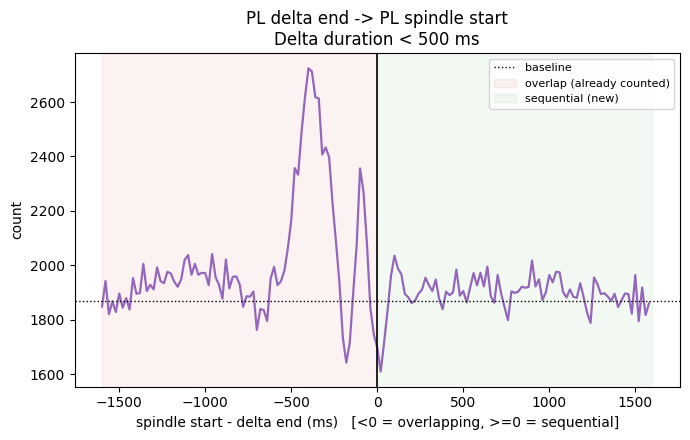

saved: 15_histogram_end_start_under500ms_PL_RSC


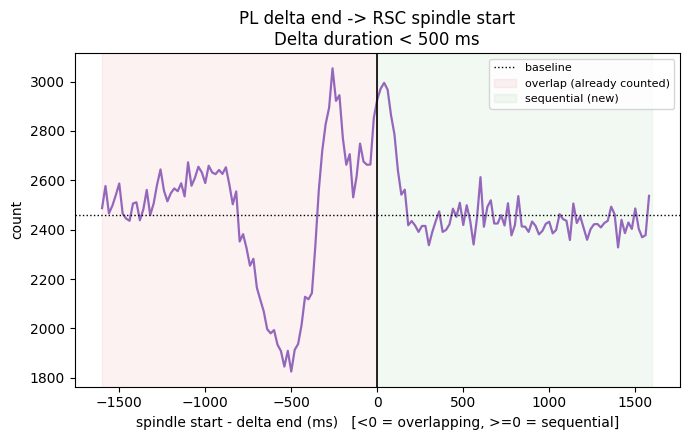

saved: 15_histogram_end_start_under500ms_PL_HPC


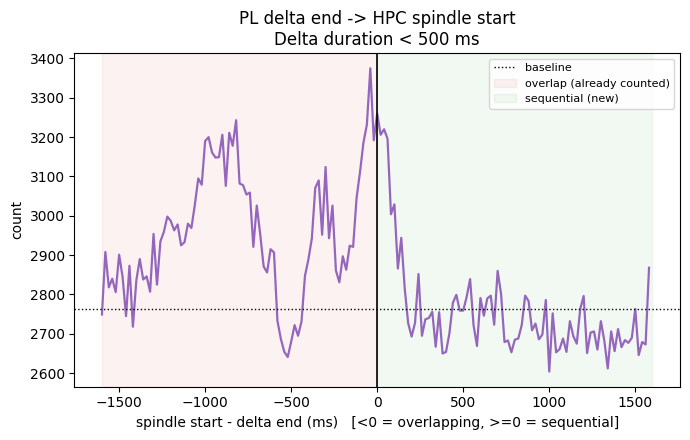

saved: 15_histogram_end_start_under500ms_RSC_PL


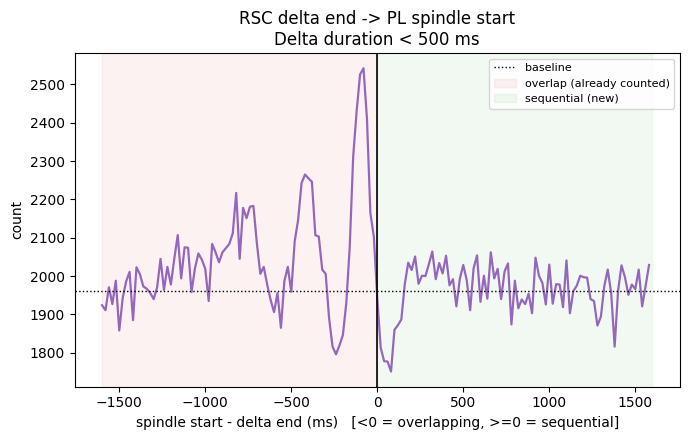

saved: 15_histogram_end_start_under500ms_RSC_RSC


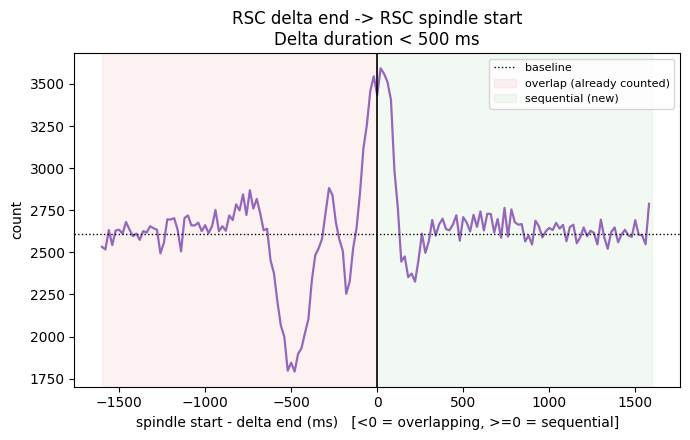

saved: 15_histogram_end_start_under500ms_RSC_HPC


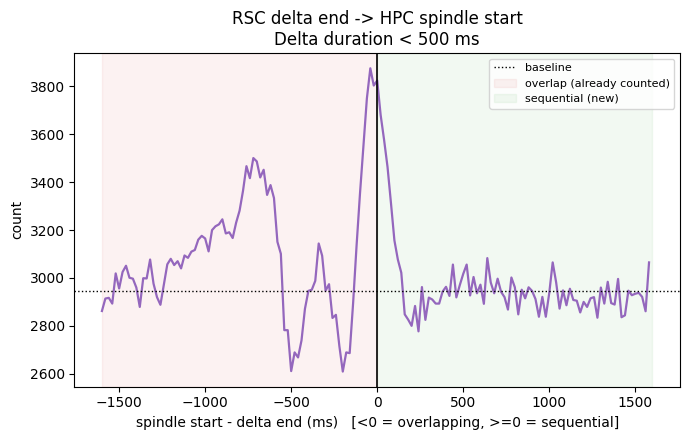

saved: 15_histogram_end_start_under500ms_HPC_PL


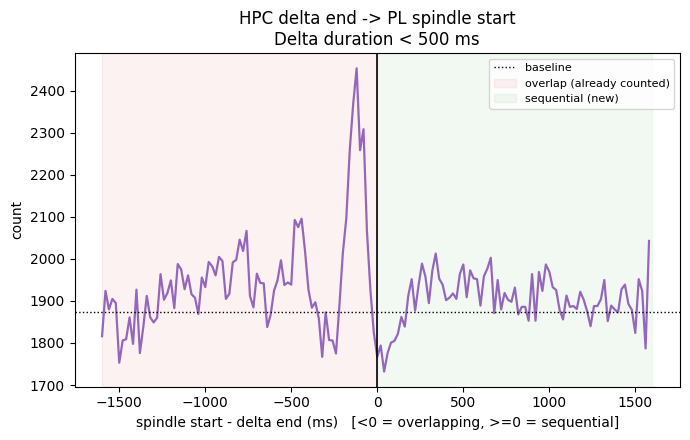

saved: 15_histogram_end_start_under500ms_HPC_RSC


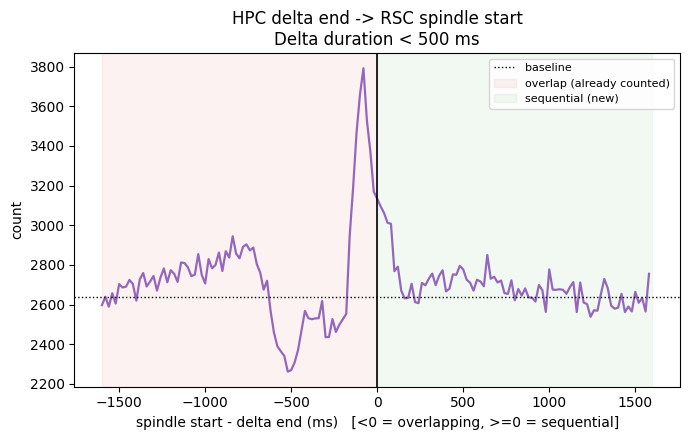

saved: 15_histogram_end_start_under500ms_HPC_HPC


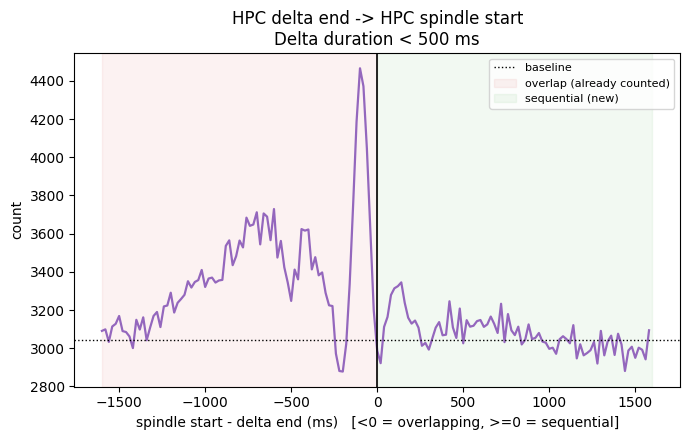

In [22]:
for (d_area, s_area), r in res_end_start_ds_short.items():
    fig, ax = plt.subplots(figsize=(7, 4.5))

    ax.plot(left_es, r["counts"], color="tab:purple", lw=1.6)
    ax.axhline(r["baseline"], color="k", lw=1, ls=":", label="baseline")
    ax.axvline(0, color="k", lw=1.2)

    ax.axvspan(
        EDGES_ES[0], 0,
        color="tab:red", alpha=0.06,
        label="overlap (already counted)"
    )
    ax.axvspan(
        0, EDGES_ES[-1],
        color="tab:green", alpha=0.06,
        label="sequential (new)"
    )

    ax.set_xlabel(
        "spindle start - delta end (ms)   [<0 = overlapping, >=0 = sequential]"
    )
    ax.set_ylabel("count")
    ax.set_title(
        f"{d_area} delta end -> {s_area} spindle start\n"
        "Delta duration < 500 ms"
    )

    ax.legend(fontsize=8)
    plt.tight_layout()

    save_fig(fig, f"15_histogram_end_start_under500ms_{d_area}_{s_area}")
    plt.show()

---
# Surrogate null

## Can every bout be shifted?

Bouts shorter than twice the minimum shift are skipped. Fine if under ~1% of events are lost.

In [ ]:
# dur   = bout_dur["nrem_bout_duration_s"]
# short = bout_dur.loc[dur <= 2.0, BOUT_KEYS]
# lost_d = dlt.merge(short, on=BOUT_KEYS).shape[0]
# lost_s = spn.merge(short, on=BOUT_KEYS).shape[0]
#
# print(f"bouts too short at the 1 s default: {(dur <= 2).sum()} of {len(dur)} "
#       f"({100*(dur <= 2).mean():.2f}%)")
# print(f"  deltas lost   {lost_d:>8,} of {len(dlt):>9,} ({100*lost_d/len(dlt):.3f}%)")
# print(f"  spindles lost {lost_s:>8,} of {len(spn):>9,} ({100*lost_s/len(spn):.3f}%)")

### Working sample (not used here)

Commented out in the 16-rat version, see `Task2d_delta_spindle_full.ipynb`.

In [ ]:
# all_bouts = pd.concat([r[BOUT_KEYS] for r in ds.values()], ignore_index=True).drop_duplicates()
# sample = all_bouts.sample(n=min(2000, len(all_bouts)), random_state=0)
#
# dlt_s = dlt.merge(sample, on=BOUT_KEYS)
# spn_s = spn.merge(sample, on=BOUT_KEYS)
#
# print("sample bouts:", len(sample))
# print("sample rows :", f"{len(dlt_s):,} deltas |", f"{len(spn_s):,} spindles")

## Circular-shift surrogate

Spindle train shifted within each recording's NREM time.

Commented out in the 16-rat version.

Tail z should be close to zero.

In [ ]:
# import pickle
# import surrogate as sg
#
# CKPT_DIR = OUT / "task2d_16rats_checkpoints"
# CKPT_DIR.mkdir(parents=True, exist_ok=True)
#
# def make_checkpoint_fn(tag):
#     path = CKPT_DIR / f"{tag}.pkl"
#     def _fn(partial):
#         with open(path, "wb") as f:
#             pickle.dump(partial, f)
#         print(f"    checkpoint saved: {path.name} ({partial['n_done']}/1000 iters)")
#     return _fn
#
# res_surr = {}
# for d_area, s_area in PAIRS:
#     pair_label = f"{d_area} delta - {s_area} spindle"
#     print(f"--- {pair_label} ---")
#     ckpt_path = CKPT_DIR / f"step13_16rats_full_{d_area}_{s_area}.pkl"
#     resume = None
#     if ckpt_path.exists():
#         with open(ckpt_path, "rb") as f:
#             resume = pickle.load(f)
#
#     if resume is not None and resume["n_done"] >= 1000:
#         print(f"    already complete at {resume['n_done']}/1000 -- using checkpoint directly")
#         res_surr[(d_area, s_area)] = resume
#         continue
#
#     if resume is not None:
#         print(f"    resuming from {resume['n_done']}/1000 iterations")
#     res_surr[(d_area, s_area)] = sg.surrogate_distribution(
#         dlt_s[dlt_s["area"] == d_area], spn_s[spn_s["area"] == s_area],
#         "delta", "spindle", EDGES, n_iter=1000, seed=0,
#         max_lag_ms=MAX_LAG_MS, scope="recording",
#         checkpoint_every=100, checkpoint_fn=make_checkpoint_fn(f"step13_16rats_full_{d_area}_{s_area}"),
#         resume_from=resume)

In [ ]:
# win  = (left >= WINDOW_MS[0]) & (left < WINDOW_MS[1])
# tail = (left < -BASELINE_MS) | (left >= BASELINE_MS)
#
# print(f"{'pair':<24}{'peak z':>9}{'at ms':>8}{'window z':>11}{'tail z':>9}")
# for (d_area, s_area), r in res_surr.items():
#     pair_label = f"{d_area} delta - {s_area} spindle"
#     print(f"{pair_label:<24}{np.nanmax(r['z']):>9.1f}{int(left[np.nanargmax(r['z'])]):>8}"
#           f"{np.nanmean(r['z'][win]):>11.1f}{np.nanmean(r['z'][tail]):>9.2f}")

In [ ]:
# # 3x3 grid: rows = delta area, columns = spindle area (AREAS order).
# fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharex=True, sharey=True)
# for (d_area, s_area), r in res_surr.items():
#     ax = axes[AREAS.index(d_area), AREAS.index(s_area)]
#     ax.fill_between(left, r["mu"] - 2*r["sd"], r["mu"] + 2*r["sd"],
#                     color="0.75", alpha=0.6, label="surrogate +/-2 SD")
#     ax.plot(left, r["mu"],   color="0.4",     lw=1,   label="surrogate mean")
#     ax.plot(left, r["real"], color="tab:red", lw=1.6, label="observed")
#     ax.axvline(0, color="k", lw=0.8)
#     ax.set_title(f"{d_area} delta vs {s_area} spindle", fontsize=10)
# for i, d_area in enumerate(AREAS):
#     axes[i, 0].set_ylabel(f"count\n({d_area} delta)")
# for j, s_area in enumerate(AREAS):
#     axes[-1, j].set_xlabel(f"lag (ms)\n({s_area} spindle)")
# axes[0, 0].legend(fontsize=8)
# fig.suptitle("Circular-shift surrogate, by pair (rows: delta area, cols: spindle area)")
# plt.tight_layout()
# save_fig(fig, "03_surrogate")
# plt.show()

### Surrogate for the unique-spindle count

Null for Yixiao's one-event rule (fraction of spindles coupled).

In [ ]:
# from coupling_unique import count_sequences_unique
#
# def _one_unique_iter(first_df, s, first_wave, second_wave, sp, rng,
#                      min_shift_ms, scope, window_ms):
#     """One circular-shift iteration for the unique-count null (mirrors the
#     loop body inside surrogate.surrogate_unique_count)."""
#     parts = []
#     if scope == "recording":
#         for _, grp in s.groupby(sg.REC_KEYS):
#             sh = sg._shift_within_recording(grp, sp, rng, min_shift_ms)
#             if sh is not None:
#                 parts.append(sh)
#     else:
#         spans = sg._bout_spans(s, sp)
#         for key, grp in s.groupby(sg.BOUT_KEYS):
#             if key not in spans.index:
#                 continue
#             lo, hi = spans.loc[key, "lo"], spans.loc[key, "hi"]
#             pk = sg.circular_shift_peaks(grp[sp].to_numpy(), lo, hi, rng, min_shift_ms)
#             if pk is None:
#                 continue
#             sh = grp.copy()
#             sh[sp] = pk
#             parts.append(sh)
#
#     if not parts:
#         return np.nan
#     shifted = pd.concat(parts, ignore_index=True)
#     return count_sequences_unique(first_df, shifted, first_wave, second_wave,
#                                   window_ms=window_ms)["n_sequences"].sum()
#
#
# def surrogate_unique_count_ckpt(first_df, second_df, first_wave, second_wave,
#                                 window_ms=None, n_iter=1000, seed=0,
#                                 min_shift_ms=1000, scope="recording",
#                                 checkpoint_every=None, checkpoint_fn=None,
#                                 resume_from=None, verbose=True):
#     """surrogate.surrogate_unique_count, with checkpoint/resume added."""
#     obs = count_sequences_unique(first_df, second_df, first_wave, second_wave,
#                                  window_ms=window_ms)
#     real = int(obs["n_sequences"].sum())
#     n_second = int(obs[f"n_{second_wave}"].sum())
#
#     sp = f"{second_wave}_peak_index"
#     s = second_df.dropna(subset=sg.BOUT_KEYS + [sp])
#
#     rng = np.random.default_rng(seed)
#     null = np.full(n_iter, np.nan)
#     start = 0
#
#     if resume_from is not None:
#         prev_n = min(int(resume_from.get("n_done", 0)), n_iter)
#         null[:prev_n] = resume_from["null"][:prev_n]
#         start = prev_n
#         if verbose:
#             print(f"    resuming from {start}/{n_iter} iterations")
#         for _ in range(start):   # advance the RNG to match a from-scratch run
#             _one_unique_iter(first_df, s, first_wave, second_wave, sp, rng,
#                              min_shift_ms, scope, window_ms)
#
#     for i in range(start, n_iter):
#         null[i] = _one_unique_iter(first_df, s, first_wave, second_wave, sp,
#                                    rng, min_shift_ms, scope, window_ms)
#         done = i + 1
#         if verbose and done % 100 == 0:
#             print(f"    {done}/{n_iter}")
#         if checkpoint_every and checkpoint_fn and done % checkpoint_every == 0:
#             checkpoint_fn({"null": null.copy(), "real": real,
#                           "n_second": n_second, "n_done": done})
#
#     mu, sdv = np.nanmean(null), np.nanstd(null)
#     p = (1 + np.nansum(null >= real)) / (1 + np.sum(~np.isnan(null)))
#     return {"real": real, "null": null, "mu": float(mu), "sd": float(sdv),
#             "z": float((real - mu) / sdv) if sdv > 0 else np.nan,
#             "p": float(p), "ratio": float(real / mu) if mu > 0 else np.nan,
#             "n_spindle": n_second}

In [ ]:
# res_unique = {}
# for d_area, s_area in PAIRS:
#     pair_label = f"{d_area} delta - {s_area} spindle"
#     ckpt_path = CKPT_DIR / f"step13b_16rats_full_{d_area}_{s_area}.pkl"
#     resume = None
#     if ckpt_path.exists():
#         with open(ckpt_path, "rb") as f:
#             resume = pickle.load(f)
#
#     if resume is not None and resume["n_done"] >= 1000:
#         print(f"{pair_label}: already complete at {resume['n_done']}/1000 -- using checkpoint directly")
#         mu, sdv = np.nanmean(resume["null"]), np.nanstd(resume["null"])
#         real = resume["real"]
#         u = {"real": real, "null": resume["null"], "mu": float(mu), "sd": float(sdv),
#              "z": float((real - mu) / sdv) if sdv > 0 else np.nan,
#              "p": float((1 + np.nansum(resume["null"] >= real))
#                         / (1 + np.sum(~np.isnan(resume["null"])))),
#              "ratio": float(real / mu) if mu > 0 else np.nan,
#              "n_spindle": resume["n_second"]}
#         res_unique[(d_area, s_area)] = u
#         print(f"{pair_label:<22}: observed {u['real']:>7,} of {u['n_spindle']:>7,} spindles "
#               f"({100*u['real']/u['n_spindle']:>5.1f}%) | null {u['mu']:>8,.0f} "
#               f"| ratio {u['ratio']:.3f} | z {u['z']:+6.1f}")
#         continue
#
#     if resume is not None:
#         print(f"{pair_label}: resuming from {resume['n_done']}/1000 iterations")
#
#     u = surrogate_unique_count_ckpt(
#         dlt_s[dlt_s["area"] == d_area], spn_s[spn_s["area"] == s_area],
#         "delta", "spindle", window_ms=WINDOW_MS,
#         n_iter=1000, seed=0, scope="recording", verbose=False,
#         checkpoint_every=100, checkpoint_fn=make_checkpoint_fn(f"step13b_16rats_full_{d_area}_{s_area}"),
#         resume_from=resume)
#     res_unique[(d_area, s_area)] = u
#     print(f"{pair_label:<22}: observed {u['real']:>7,} of {u['n_spindle']:>7,} spindles "
#           f"({100*u['real']/u['n_spindle']:>5.1f}%) | null {u['mu']:>8,.0f} "
#           f"| ratio {u['ratio']:.3f} | z {u['z']:+6.1f}")

# Delta phase (Hilbert transform)

Are spindles locked to the phase of the ongoing delta rhythm?

Continuous LFP band-pass filtered, Hilbert transform for phase, at spindle peaks.

Delta band 0.5-4 Hz (confirmed with Yixiao). The LFP is read one trial file at a time from `PreprocessedData` (peak indices are within-trial), on the channel the delta waves were detected on.

In [ ]:
import io
import shutil
import time as _time

import scipy.io
from scipy.signal import butter, hilbert, sosfiltfilt

FS_HZ = 1000.0  # 1 sample = 1 ms
DELTA_BAND = (0.5, 4.0)  # Hz (confirmed with Yixiao)

# ROOT / Rat_HM_Ephys_TD_Analysis_R1_8-or-R9_16 / <rat-group> / PreprocessedData /
#   <area> / <rat> / <date> / <phase> / chan<channel>_<trial>.mat   (unsplit days: chan<channel>.mat)
ANALYSIS_GROUPS = {
    "Rat_HM_Ephys_TD_Analysis_R1_8": ["R1-4", "R5-8"],
    "Rat_HM_Ephys_TD_Analysis_R9_16": ["R9-12", "R13-16"],
}


def _find_preproc_rat_dir(area, rat):
    """PreprocessedData/<area>/<rat>, trying every ANALYSIS_GROUPS folder."""
    for analysis, subgroups in ANALYSIS_GROUPS.items():
        for sub in subgroups:
            cand = ROOT / analysis / sub / "PreprocessedData" / area / str(rat)
            if cand.exists():
                return cand
    return None


def channel_for(delta_df, rat, area, date):
    """Recording channel of this rat/area/date's delta detection (from the event table)."""
    rows = delta_df[
        (delta_df["rat"] == rat)
        & (delta_df["area"] == area)
        & (delta_df["date"] == date)
    ]
    chans = rows["channel"].dropna().unique()
    if len(chans) == 0:
        return None
    if len(chans) > 1:
        print(
            f"    warning: rat {rat} {area} {pd.Timestamp(date).date()} has "
            f"several channels {list(chans)}, using {chans[0]}"
        )
    return int(chans[0])


class UnreadableMatFile(FileNotFoundError):
    """The .mat file exists but could not be read (network / drive problem)."""


unreadable_lfp = []  # files skipped after all retries


def _load_mat_signal(
    path, chunk_bytes=8 * 1024 * 1024, attempts=6, waits=(10, 20, 30, 40, 60)
):
    """'data' array of one .mat file. Reading straight off Z: with loadmat(path)
    failed with OSError [Errno 22] part-way through a file, so the file is copied
    into memory in 8 MB pieces first, and a failed read is retried."""
    last = None
    for attempt in range(1, attempts + 1):
        try:
            buf = io.BytesIO()
            with open(path, "rb") as f:
                shutil.copyfileobj(f, buf, chunk_bytes)
            buf.seek(0)
            return scipy.io.loadmat(buf)["data"].squeeze()
        except OSError as e:
            last = e
            if attempt < attempts:
                _time.sleep(waits[min(attempt - 1, len(waits) - 1)])
    raise UnreadableMatFile(f"{path} unreadable after {attempts} attempts: {last}")


def load_trial_lfp(rat, date, trial, area, channel, phase="postsleep"):
    """LFP of one trial ('data' in chan<channel>_<trial>.mat, or chan<channel>.mat
    for unsplit days). None if the file isn't there."""
    rat_dir = _find_preproc_rat_dir(area, rat)
    if rat_dir is None:
        return None
    phase_dir = rat_dir / pd.to_datetime(date).strftime("%Y%m%d") / phase
    for f in (
        phase_dir / f"chan{channel}_{int(trial)}.mat",
        phase_dir / f"chan{channel}.mat",
    ):
        if f.exists():
            try:
                return _load_mat_signal(f).ravel()
            except UnreadableMatFile as e:
                unreadable_lfp.append(str(e))
                return None
    return None


def bandpass_delta(signal, fs=FS_HZ, band=DELTA_BAND, order=4):
    """Zero-phase Butterworth band-pass into the delta band. Second-order sections:
    the (b, a) form of this filter is unstable at 1000 Hz (output blows up)."""
    sos = butter(order, band, btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, signal)


def delta_phase_at_times(signal, fs, event_sample_indices):
    """Delta phase (radians, -pi..pi) at each sample index; NaN outside the trace."""
    phase = np.angle(hilbert(bandpass_delta(signal, fs=fs)))
    out = np.full(len(event_sample_indices), np.nan)
    ok = (event_sample_indices >= 0) & (event_sample_indices < len(phase))
    out[ok] = phase[event_sample_indices[ok]]
    return out


def event_phases(ev_df, peak_col, area, delta_df):
    """Delta phase in `area` at every event peak, one trial file at a time
    (peak indices are within-trial sample indices)."""
    out = []
    for (rat, date, trial), g in ev_df.groupby(["rat", "date", "trial"]):
        channel = channel_for(delta_df, rat, area, date)
        if channel is None:
            continue
        sig = load_trial_lfp(rat, date, trial, area, channel)
        if sig is None:
            continue
        peaks = g[peak_col].dropna().to_numpy().astype(int)
        if len(peaks):
            out.append(delta_phase_at_times(sig, FS_HZ, peaks))
    ph = np.concatenate(out) if out else np.array([])
    return ph[~np.isnan(ph)]


def event_phase_diffs(ev_df, peak_col, area_a, area_b, delta_df):
    """Delta phase difference area_a - area_b (wrapped to -pi..pi) at every event peak."""
    out = []
    for (rat, date, trial), g in ev_df.groupby(["rat", "date", "trial"]):
        ch_a = channel_for(delta_df, rat, area_a, date)
        ch_b = channel_for(delta_df, rat, area_b, date)
        if ch_a is None or ch_b is None:
            continue
        sig_a = load_trial_lfp(rat, date, trial, area_a, ch_a)
        sig_b = load_trial_lfp(rat, date, trial, area_b, ch_b)
        if sig_a is None or sig_b is None:
            continue
        peaks = g[peak_col].dropna().to_numpy().astype(int)
        if len(peaks):
            d = delta_phase_at_times(sig_a, FS_HZ, peaks) - delta_phase_at_times(
                sig_b, FS_HZ, peaks
            )
            out.append((d[~np.isnan(d)] + np.pi) % (2 * np.pi) - np.pi)
    return np.concatenate(out) if out else np.array([])

In [ ]:
def rayleigh_test(phases):
    """Rayleigh test for non-uniformity of a circular distribution.

    Returns (R, z, p). Standard large-sample approximation (Zar,
    Biostatistical Analysis). Valid for n > ~10; for smaller samples treat
    the p-value as approximate."""
    n = len(phases)
    if n == 0:
        return np.nan, np.nan, np.nan
    C = np.sum(np.cos(phases))
    S = np.sum(np.sin(phases))
    R = np.sqrt(C**2 + S**2) / n
    z = n * R**2
    p = np.exp(-z) * (
        1
        + (2 * z - z**2) / (4 * n)
        - (24 * z - 132 * z**2 + 76 * z**3 - 9 * z**4) / (288 * n**2)
    )
    return R, z, max(min(p, 1.0), 0.0)


def circular_hist(ax, phases, bins=24, color="tab:purple"):
    """Phase histogram on a polar axis."""
    counts, edges = np.histogram(phases, bins=bins, range=(-np.pi, np.pi))
    width = edges[1] - edges[0]
    ax.bar(
        edges[:-1],
        counts,
        width=width,
        align="edge",
        color=color,
        alpha=0.75,
        edgecolor="white",
    )
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)


# delta phase at each spindle peak, per delta area
phase_by_area = {}
for area in AREAS:
    phase_by_area[area] = event_phases(spn, "spindle_peak_index", area, dlt)
    print(f"{area}: {len(phase_by_area[area])} spindle-phase samples collected")

In [ ]:
# circular histogram + Rayleigh test per area
fig, axes = plt.subplots(
    1, len(AREAS), figsize=(4.5 * len(AREAS), 4.5), subplot_kw={"projection": "polar"}
)
axes = np.atleast_1d(axes)
for ax, area in zip(axes, AREAS):
    phases = phase_by_area[area]
    circular_hist(ax, phases)
    if len(phases):
        R, z, p = rayleigh_test(phases)
        ax.set_title(f"{area}\nRayleigh R={R:.3f}, p={p:.4f}", fontsize=10)
    else:
        ax.set_title(f"{area}\n(no data yet)", fontsize=10)
plt.tight_layout()
save_fig(fig, "16_delta_phase_per_area")
plt.show()

In [ ]:
# phase difference between two areas at each spindle peak (wrapped to -pi..pi)
from itertools import combinations

cross_area_diffs = {}
for area_a, area_b in combinations(AREAS, 2):
    cross_area_diffs[(area_a, area_b)] = event_phase_diffs(
        spn, "spindle_peak_index", area_a, area_b, dlt
    )

if unreadable_lfp:
    print(f"{len(unreadable_lfp)} LFP files could not be read and were skipped:")
    for msg in unreadable_lfp:
        print("   ", msg)

fig, axes = plt.subplots(
    1,
    len(cross_area_diffs),
    figsize=(4.5 * len(cross_area_diffs), 4.5),
    subplot_kw={"projection": "polar"},
)
axes = np.atleast_1d(axes)
for ax, (pair, diffs) in zip(axes, cross_area_diffs.items()):
    circular_hist(ax, diffs, color="tab:teal")
    if len(diffs):
        R, z, p = rayleigh_test(diffs)
        ax.set_title(f"{pair[0]}-{pair[1]}\nRayleigh R={R:.3f}, p={p:.4f}", fontsize=9)
    else:
        ax.set_title(f"{pair[0]}-{pair[1]}\n(no data yet)", fontsize=9)
plt.tight_layout()
save_fig(fig, "17_cross_area_delta_phase_diff")
plt.show()

---
# Surrogate null

## Can every bout be shifted?

Bouts shorter than twice the minimum shift are skipped. Fine if under ~1% of events are lost.

In [ ]:
dur = bout_dur["nrem_bout_duration_s"]
short = bout_dur.loc[dur <= 2.0, BOUT_KEYS]
lost_d = dlt.merge(short, on=BOUT_KEYS).shape[0]
lost_s = spn.merge(short, on=BOUT_KEYS).shape[0]

print(
    f"bouts too short at the 1 s default: {(dur <= 2).sum()} of {len(dur)} "
    f"({100 * (dur <= 2).mean():.2f}%)"
)
print(
    f"  deltas lost   {lost_d:>8,} of {len(dlt):>9,} ({100 * lost_d / len(dlt):.3f}%)"
)
print(
    f"  spindles lost {lost_s:>8,} of {len(spn):>9,} ({100 * lost_s / len(spn):.3f}%)"
)

---
# Does coupling change with learning?

## HC vs Training per rat

Per rat, paired. With n = 7 a sign test needs 7/7 for p = 0.008 (6/7 gives 0.06).

In [ ]:
MIN_NREM_MIN = 10  # minutes of NREM sleep required for a rat-day to count
# in this per-rat step (not for the histograms)

day_nrem = bout_dur.groupby(["rat", "date"])["nrem_bout_duration_s"].sum() / 60
good_days = day_nrem[day_nrem >= MIN_NREM_MIN].reset_index()[["rat", "date"]]
print(
    f"rat-days: {day_nrem.shape[0]} total -> {len(good_days)} with >= {MIN_NREM_MIN} min "
    f"NREM ({day_nrem.shape[0] - len(good_days)} dropped)"
)


def ratio_per_rat(dlt_df, spn_df, d_area, s_area, split_col):
    """One D->S ratio per rat per level of split_col, for one pair.

    Only rat-days in good_days (>= MIN_NREM_MIN minutes of NREM) are used;
    nrem_days = number of those rat-days behind each ratio.
    """
    d = dlt_df[dlt_df["area"] == d_area].merge(good_days, on=["rat", "date"])
    s_all = spn_df[spn_df["area"] == s_area].merge(good_days, on=["rat", "date"])
    rows = []
    for (rat, level), dg in d.groupby(["rat", split_col], observed=True):
        sg = s_all[(s_all["rat"] == rat) & (s_all[split_col] == level)]
        if sg.empty or dg.empty:
            continue
        lg = lh.collect_lags(dg, sg, "delta", "spindle", max_lag_ms=MAX_LAG_MS)
        if len(lg) == 0:
            continue
        n_days = dg[["rat", "date"]].drop_duplicates().shape[0]
        res = lh.summarise(
            lg, EDGES, baseline_ms=BASELINE_MS, windows=WINDOWS, verbose=False
        )
        rows.append(
            {
                "rat": rat,
                split_col: level,
                "pair": f"{d_area}_{s_area}",
                "d_area": d_area,
                "s_area": s_area,
                "ratio": res["windows"]["D->S"]["ratio"],
                "peak_ms": res["peak_ms"],
                "pairs": len(lg),
                "nrem_days": n_days,
            }
        )
    return pd.DataFrame(rows)


def compare(table, split_col, levels, ref, pairs=None):
    """Paired comparison of each level against `ref`, per pair."""
    pairs = pairs or PAIRS
    for d_area, s_area in pairs:
        pair_label = f"{d_area} delta - {s_area} spindle"
        sub = table[table["pair"] == f"{d_area}_{s_area}"]
        w = sub.pivot(index="rat", columns=split_col, values="ratio").dropna()
        if len(w) < 3:
            print(f"{pair_label}: only {len(w)} rats -- skipping")
            continue
        n_days = sub.pivot(index="rat", columns=split_col, values="nrem_days")
        print(f"\n{pair_label}  (n={len(w)} rats)")
        print(
            "  NREM-qualifying days per rat, by level: "
            + " | ".join(
                f"{l} median {n_days[l].median():.0f}"
                for l in levels
                if l in n_days.columns
            )
        )
        print("  means: " + " | ".join(f"{l} {w[l].mean():.3f}" for l in levels))
        for l in [x for x in levels if x != ref]:
            d = w[l] - w[ref]
            print(
                f"  {l:>7} vs {ref}: {d.mean():+.3f} | "
                f"{int((d > 0).sum())}/{len(w)} rats higher"
            )


hc_tr = pd.concat(
    [
        ratio_per_rat(dlt_ctx, spn_ctx, d_area, s_area, "group")
        for d_area, s_area in PAIRS
    ],
    ignore_index=True,
)
hc_tr = hc_tr[hc_tr["group"].isin(["HC", "Training"])]

print("rats with enough qualifying days per cell:")
print(hc_tr.groupby(["pair", "group"])["rat"].nunique().to_string())

In [ ]:
compare(hc_tr, "group", ["HC", "Training"], ref="HC")

## Training split by session type

Training split into new goal location, probe and normal. Prediction: NGL highest.

In [ ]:
tr_type = pd.concat(
    [
        ratio_per_rat(dlt_ctx, spn_ctx, d_area, s_area, "session_type")
        for d_area, s_area in PAIRS
    ],
    ignore_index=True,
)

print(tr_type.groupby(["pair", "session_type"])["rat"].nunique().to_string())

In [ ]:
compare(tr_type, "session_type", ["NGL", "probe", "normal"], ref="normal")

## HC vs each training type

Sleep after new learning vs HC. Third version of the same question, so treat results as leads.

In [ ]:
def add_condition4(df):
    """HC and the three training types in one column."""
    df = df.copy()
    df["condition4"] = np.where(
        df["group"] == "HC", "HC", df["session_type"].astype(str)
    )
    df.loc[~df["condition4"].isin(["HC", "NGL", "probe", "normal"]), "condition4"] = (
        np.nan
    )
    return df


four = pd.concat(
    [
        ratio_per_rat(
            add_condition4(dlt_ctx),
            add_condition4(spn_ctx),
            d_area,
            s_area,
            "condition4",
        )
        for d_area, s_area in PAIRS
    ],
    ignore_index=True,
)

compare(four, "condition4", ["HC", "NGL", "probe", "normal"], ref="HC")

---
# Coupling over time

Per-rat Spearman + permutation on the D->S ratio (fraction of spindles with a delta 100-1300 ms before, `count_sequences_unique`).

## Per-day ratio table

Computed once per pair and used by all plots below. Rat-days with less than 10 min of NREM (`MIN_NREM_MIN`) are removed and listed in a footnote under each plot.

In [ ]:
# COHORTS defined here because the plots below need it
COHORTS = {
    "rats1-4 (build-up)": [r for r in RATS if r <= 4],
    "rats5-8 (build-up)": [r for r in RATS if 4 < r <= 8],
    "rats9-12 (update)": [r for r in RATS if 8 < r <= 12],
    "rats13-16 (update)": [r for r in RATS if r > 12],
}

In [ ]:
from modules.event_coupling.coupling_unique import count_sequences_unique

# days since each rat's first recording (added here if missing)
if "days_elapsed" not in dlt_ctx.columns:
    first = dlt_ctx.groupby("rat")["date"].transform("min")
    dlt_ctx["days_elapsed"] = (dlt_ctx["date"] - first).dt.days


def per_day_sequence_ratio(dlt_df, spn_df, d_area, s_area, window_ms):
    """Per rat-day: fraction of spindles (in s_area) with at least one delta
    (in d_area) preceding them within window_ms -- Yixiao's one-event rule,
    applied day by day instead of pooled across the whole dataset. Mirrors
    the cross-regional notebooks' per_day_cooccurrence (n_coupled/n_seed),
    but using the sequential (lag-window) definition of coupling instead of
    the overlap-based nearest-neighbor one."""
    d_all = dlt_df[dlt_df["area"] == d_area]
    s_all = spn_df[spn_df["area"] == s_area]
    rows = []
    for (rat, date), sg in s_all.groupby(["rat", "date"]):
        dg = d_all[(d_all["rat"] == rat) & (d_all["date"] == date)]
        if dg.empty or sg.empty:
            continue
        u = count_sequences_unique(dg, sg, "delta", "spindle", window_ms=window_ms)
        n_coupled, n_seed = int(u["n_sequences"].sum()), int(u["n_spindle"].sum())
        if n_seed == 0:
            continue
        meta = dlt_df[(dlt_df["rat"] == rat) & (dlt_df["date"] == date)]
        if meta.empty:
            continue
        meta = meta.iloc[0]
        rows.append(
            {
                "rat": rat,
                "date": date,
                "n_coupled": n_coupled,
                "n_seed": n_seed,
                "group": meta["group"],
                "days_elapsed": meta["days_elapsed"],
                "gl_num": meta.get("gl_num"),
                "session_num": meta.get("session_num"),
            }
        )
    return pd.DataFrame(rows)


# NREM cutoff: rat-days with < MIN_NREM_MIN minutes of NREM are removed
# here and listed in the footnote of each over-time plot
_nrem = {(int(r), pd.Timestamp(d).normalize()): m for (r, d), m in day_nrem.items()}


def apply_nrem_cutoff(daily_df):
    """Split daily_df into rat-days with >= MIN_NREM_MIN minutes of NREM and the removed ones."""
    if daily_df.empty:
        return daily_df, daily_df.assign(nrem_min=[])
    mins = pd.Series(
        [
            _nrem.get((int(r), pd.Timestamp(d).normalize()), 0.0)
            for r, d in zip(daily_df["rat"], daily_df["date"])
        ],
        index=daily_df.index,
    )
    keep = mins >= MIN_NREM_MIN
    removed = daily_df.loc[~keep, ["rat", "date", "group"]].assign(
        nrem_min=mins[~keep].values
    )
    return daily_df[keep].reset_index(drop=True), removed.reset_index(drop=True)


def nrem_removed_keys(d_area, s_area):
    rem = nrem_removed.get((d_area, s_area))
    return set() if rem is None else set(zip(rem["rat"], rem["date"]))


def add_nrem_footnote(fig, d_area, s_area, groups):
    """List the rat-days removed by the NREM cutoff under the figure."""
    rem = nrem_removed.get((d_area, s_area))
    if rem is None or rem.empty:
        return
    rem = rem[rem["group"].isin(groups)]
    if rem.empty:
        return
    parts = []
    for rat, g in rem.groupby("rat"):
        days = ", ".join(
            f"{pd.Timestamp(d).date()} {grp} ({m:.1f} min)"
            for d, grp, m in zip(g["date"], g["group"], g["nrem_min"])
        )
        parts.append(f"Rat {rat}: {days}")
    note = f"Removed, < {MIN_NREM_MIN} min NREM: " + " | ".join(parts)
    old = [t for t in fig.texts if t.get_color() == "firebrick"]
    if old:
        old[0].set_text(old[0].get_text() + "\n" + note)
        fig.subplots_adjust(bottom=0.36)
    else:
        fig.subplots_adjust(bottom=0.30)
        fig.text(
            0.5,
            0.02,
            note,
            ha="center",
            va="bottom",
            fontsize=8,
            color="firebrick",
            wrap=True,
        )


nrem_removed = {}

daily_cache = {}
for d_area, s_area in PAIRS:
    daily_df = per_day_sequence_ratio(dlt_ctx, spn_ctx, d_area, s_area, WINDOW_MS)
    daily_df, nrem_removed[(d_area, s_area)] = apply_nrem_cutoff(daily_df)
    daily_cache[(d_area, s_area)] = daily_df
    print(
        f"{d_area} delta - {s_area} spindle: {len(daily_df)} rat-days with data, "
        f"{len(nrem_removed[(d_area, s_area)])} removed (< {MIN_NREM_MIN} min NREM)"
    )

## Training days over time

y = ratio. Training days only, split by cohort, x = GL_session with goal-location blocks shaded.

In [ ]:
def plot_training_overtime(daily_df, d_area, s_area):
    sub_all = daily_df.copy()
    sub_all["ratio_proxy"] = sub_all["n_coupled"] / sub_all["n_seed"].replace(0, np.nan)
    sub_all = sub_all.dropna(subset=["gl_num", "session_num", "ratio_proxy"])
    if sub_all.empty:
        print(
            f"{d_area} delta - {s_area} spindle: no GL/session-labelled data, skipping"
        )
        return

    fig, axes = plt.subplots(1, 4, figsize=(24, 4.6), sharey=True)
    for ax, (label, rats) in zip(axes, COHORTS.items()):
        sub = sub_all[sub_all["rat"].isin(rats)].copy()
        if sub.empty:
            ax.set_title(label, fontsize=11)
            continue

        sub["step"] = sub["gl_num"] * 10 + sub["session_num"]
        order = sorted(sub["step"].unique())
        pos = {s: i for i, s in enumerate(order)}
        tick_labels = [f"GL{int(s // 10)}_S{int(s % 10)}" for s in order]

        for rat in rats:
            r = sub[sub["rat"] == rat].sort_values("days_elapsed")
            if r.empty:
                continue
            g = r.groupby("step")["ratio_proxy"].mean()
            # only this rat's own steps, otherwise the line breaks at missing steps
            xs = [pos[s] for s in g.index]
            ax.plot(
                xs, g.values, marker="o", ms=4, lw=1.2, alpha=0.8, label=f"rat {rat}"
            )

        for i, s in enumerate(order):
            if int(s // 10) % 2 == 0:
                ax.axvspan(i - 0.5, i + 0.5, color="0.92", zorder=0)
        ax.set_xticks(range(len(tick_labels)))
        ax.set_xticklabels(tick_labels, rotation=90, fontsize=7)
        ax.set_title(label, fontsize=11)
        ax.legend(fontsize=7, ncol=2)
        ax.grid(alpha=0.2, lw=0.5, axis="y")

    axes[0].set_ylabel("ratio (fraction of spindles coupled)")
    fig.suptitle(
        f"{d_area} delta - {s_area} spindle  --  D->S ratio over time, Training days   "
        "(shading marks goal-location blocks)",
        fontsize=12,
    )
    plt.tight_layout()
    add_nrem_footnote(fig, d_area, s_area, ["Training"])
    save_fig(fig, f"08_training_overtime_{d_area}_{s_area}")
    plt.show()


for d_area, s_area in PAIRS:
    daily_df = daily_cache[(d_area, s_area)]
    if daily_df.empty:
        print(f"{d_area}-{s_area}: no data, skipping")
        continue
    plot_training_overtime(daily_df, d_area, s_area)

## HC days over time

Does coupling drift on HC days? x = `days_elapsed`.

In [ ]:
def plot_hc_overtime(daily_df, d_area, s_area):
    sub_all = daily_df.copy()
    sub_all["ratio_proxy"] = sub_all["n_coupled"] / sub_all["n_seed"].replace(0, np.nan)
    sub_all = sub_all[sub_all["group"] == "HC"].dropna(subset=["ratio_proxy"])
    if sub_all.empty:
        print(f"{d_area} delta - {s_area} spindle: no HC data, skipping")
        return

    fig, axes = plt.subplots(1, 4, figsize=(24, 4.6), sharey=True)
    for ax, (label, rats) in zip(axes, COHORTS.items()):
        sub = sub_all[sub_all["rat"].isin(rats)].copy()
        if sub.empty:
            ax.set_title(label, fontsize=11)
            continue

        for rat in rats:
            r = sub[sub["rat"] == rat].sort_values("days_elapsed")
            if r.empty:
                continue
            ax.plot(
                r["days_elapsed"],
                r["ratio_proxy"],
                marker="o",
                ms=4,
                lw=1.2,
                alpha=0.8,
                label=f"rat {rat}",
            )

        ax.set_title(label, fontsize=11)
        ax.set_xlabel("days elapsed")
        ax.legend(fontsize=7, ncol=2)
        ax.grid(alpha=0.2, lw=0.5, axis="y")

    axes[0].set_ylabel("ratio (fraction of spindles coupled)")
    fig.suptitle(
        f"{d_area} delta - {s_area} spindle  --  D->S ratio over time, Home-cage days",
        fontsize=12,
    )
    plt.tight_layout()
    add_nrem_footnote(fig, d_area, s_area, ["HC"])
    save_fig(fig, f"09_hc_overtime_{d_area}_{s_area}")
    plt.show()


for d_area, s_area in PAIRS:
    daily_df = daily_cache[(d_area, s_area)]
    if daily_df.empty:
        print(f"{d_area}-{s_area}: no data, skipping")
        continue
    plot_hc_overtime(daily_df, d_area, s_area)

## Normalized to the nearest HC session

Training ratio / ratio of the rat's nearest HC day (1 = same as baseline).

In [ ]:
def find_missing_points(daily_df, d_area, s_area, rats_to_check):
    """Training days with a valid GL/session label that are absent from
    daily_df entirely -- per_day_sequence_ratio's groupby skips any
    (rat, date) with zero d_area deltas or zero s_area spindles that day,
    rather than recording an explicit zero row, so comparing against
    dlt_ctx is the only way to catch this."""
    expected = dlt_ctx[
        (dlt_ctx["rat"].isin(rats_to_check))
        & (dlt_ctx["area"] == d_area)
        & (dlt_ctx["group"] == "Training")
    ]
    expected = expected.dropna(subset=["gl_num", "session_num"])[
        ["rat", "date", "gl_num", "session_num"]
    ].drop_duplicates()
    present = set(zip(daily_df["rat"], daily_df["date"])) | nrem_removed_keys(
        d_area, s_area
    )
    notes = []
    for _, row in expected.iterrows():
        if (row["rat"], row["date"]) not in present:
            date_str = (
                row["date"].date() if hasattr(row["date"], "date") else row["date"]
            )
            notes.append(
                f"Rat {row['rat']}: {date_str} (GL{int(row['gl_num'])}_S{int(row['session_num'])}) "
                f"missing -- no {d_area} delta or {s_area} spindle events that day"
            )
    return notes


def dropped_to_notes(dropped):
    notes = []
    for d in dropped:
        date_str = d["date"].date() if hasattr(d["date"], "date") else d["date"]
        notes.append(
            f"Rat {d['rat']}: {date_str} missing -- nearest two HC days "
            f"({d['nearest_hc_days_elapsed']}) both had 0 coupling"
        )
    return notes


def nearest_hc_normalize(daily_df):
    """For each training day, divide by the nearest home-cage day's
    ratio_proxy. If the nearest HC day is 0, falls back to the
    second-nearest. If that's also 0, the training day is dropped
    (capped at two attempts)."""
    daily_df = daily_df.copy()
    daily_df["ratio_proxy"] = daily_df["n_coupled"] / daily_df["n_seed"].replace(
        0, np.nan
    )
    out_rows = []
    dropped = []
    for rat, g in daily_df.groupby("rat"):
        hc = (
            g[g["group"] == "HC"]
            .dropna(subset=["ratio_proxy"])
            .sort_values("days_elapsed")
        )
        train = g[g["group"] == "Training"].dropna(
            subset=["ratio_proxy", "gl_num", "session_num"]
        )
        if hc.empty or train.empty:
            continue
        for _, row in train.iterrows():
            hc_sorted = hc.iloc[
                (hc["days_elapsed"] - row["days_elapsed"]).abs().argsort()
            ]
            used = None
            for rank, (_, hc_row) in enumerate(hc_sorted.iterrows()):
                if rank >= 2:
                    break
                if hc_row["ratio_proxy"] and hc_row["ratio_proxy"] > 0:
                    used = hc_row
                    break
            if used is None:
                nearest_two = hc_sorted.head(2)
                dropped.append(
                    {
                        "rat": rat,
                        "date": row["date"],
                        "days_elapsed": row["days_elapsed"],
                        "nearest_hc_days_elapsed": list(nearest_two["days_elapsed"]),
                    }
                )
                continue
            out_rows.append(
                {
                    **row.to_dict(),
                    "ratio": row["ratio_proxy"] / used["ratio_proxy"],
                    "nearest_hc_days_elapsed": used["days_elapsed"],
                }
            )
    return pd.DataFrame(out_rows), dropped


def plot_hc_normalized(
    norm_df, daily_df, missing_notes, d_area, s_area, norm_label, fname_tag
):
    """Shared by Steps 21 and 22 -- same GL-shaded, per-cohort layout as the
    raw over-time plot, with a chance line at 1.0 since this measure is
    meant to be read relative to that rat's own HC baseline. Footnotes any
    point missing entirely or dropped during normalization."""
    if norm_df.empty:
        print(f"{d_area} delta - {s_area} spindle: no data to normalize, skipping")
        return

    fig, axes = plt.subplots(1, 4, figsize=(24, 4.6), sharey=True)
    for ax, (label, rats) in zip(axes, COHORTS.items()):
        sub = norm_df[norm_df["rat"].isin(rats)].copy()
        if sub.empty:
            ax.set_title(label, fontsize=11)
            continue
        sub["step"] = sub["gl_num"] * 10 + sub["session_num"]
        order = sorted(sub["step"].unique())
        pos = {s: i for i, s in enumerate(order)}
        tick_labels = [f"GL{int(s // 10)}_S{int(s % 10)}" for s in order]

        for rat in rats:
            r = sub[sub["rat"] == rat]
            if len(r) < 3:
                continue
            g = r.groupby("step")["ratio"].mean()
            # only this rat's own steps, otherwise the line breaks at missing steps
            xs = [pos[s] for s in g.index]
            ax.plot(
                xs, g.values, lw=1.6, alpha=0.85, marker="o", ms=4, label=f"rat {rat}"
            )

        for i, s in enumerate(order):
            if int(s // 10) % 2 == 0:
                ax.axvspan(i - 0.5, i + 0.5, color="0.92", zorder=0)
        ax.axhline(1, color="k", lw=1.2, ls=":")
        ax.set_xticks(range(len(tick_labels)))
        ax.set_xticklabels(tick_labels, rotation=90, fontsize=7)
        ax.set_title(label, fontsize=11)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2, lw=0.5, axis="y")

    axes[0].set_ylabel("ratio")
    fig.suptitle(
        f"{d_area} delta - {s_area} spindle  --  normalized to {norm_label}   "
        "(shading marks goal-location blocks)",
        fontsize=12,
    )
    plt.tight_layout()

    if missing_notes:
        fig.subplots_adjust(bottom=0.28)
        footnote = "Missing point(s): " + " | ".join(missing_notes)
        fig.text(
            0.5,
            0.02,
            footnote,
            ha="center",
            va="bottom",
            fontsize=8,
            color="firebrick",
            wrap=True,
        )

    add_nrem_footnote(fig, d_area, s_area, ["Training", "HC"])
    save_fig(fig, f"{fname_tag}_{d_area}_{s_area}")
    plt.show()


nearest_hcnorm_results = {}
all_dropped = []
for d_area, s_area in PAIRS:
    daily_df = daily_cache[(d_area, s_area)]
    if daily_df.empty:
        continue
    norm_df, dropped = nearest_hc_normalize(daily_df)
    nearest_hcnorm_results[(d_area, s_area)] = norm_df
    all_dropped.append((f"{d_area}-{s_area}", dropped))
    all_rats_in_cohorts = [r for rats in COHORTS.values() for r in rats]
    missing_notes = find_missing_points(
        daily_df, d_area, s_area, all_rats_in_cohorts
    ) + dropped_to_notes(dropped)
    plot_hc_normalized(
        norm_df,
        daily_df,
        missing_notes,
        d_area,
        s_area,
        "nearest home-cage session",
        "10_nearesthcnorm",
    )

print()
print(
    "=== Points removed (nearest-HC): both nearest and second-nearest HC days were 0 ==="
)
any_dropped = False
for name, dropped in all_dropped:
    for d in dropped:
        any_dropped = True
        print(
            f"  [{name}] rat {d['rat']}, {d['date']} (days_elapsed={d['days_elapsed']}): "
            f"nearest two HC days ({d['nearest_hc_days_elapsed']}) both had 0 coupling"
        )
if not any_dropped:
    print("  none -- every training day found a usable HC baseline within two tries")

## Normalized to the average HC session

Training ratio / average of the rat's nonzero HC days.

In [ ]:
def average_hc_normalize(daily_df):
    daily_df = daily_df.copy()
    daily_df["ratio_proxy"] = daily_df["n_coupled"] / daily_df["n_seed"].replace(
        0, np.nan
    )
    out_rows = []
    skipped = []
    for rat, g in daily_df.groupby("rat"):
        hc = g[g["group"] == "HC"].dropna(subset=["ratio_proxy"])
        hc_nonzero = hc[hc["ratio_proxy"] > 0]
        train = g[g["group"] == "Training"].dropna(
            subset=["ratio_proxy", "gl_num", "session_num"]
        )
        if train.empty:
            continue
        if hc_nonzero.empty:
            skipped.append({"rat": rat, "n_hc_days": len(hc)})
            continue
        avg_hc = hc_nonzero["ratio_proxy"].mean()
        for _, row in train.iterrows():
            out_rows.append(
                {
                    **row.to_dict(),
                    "ratio": row["ratio_proxy"] / avg_hc,
                    "avg_hc_value": avg_hc,
                    "n_hc_days_used": len(hc_nonzero),
                }
            )
    return pd.DataFrame(out_rows), skipped


avg_hcnorm_results = {}
all_skipped = []
for d_area, s_area in PAIRS:
    daily_df = daily_cache[(d_area, s_area)]
    if daily_df.empty:
        continue
    norm_df, skipped = average_hc_normalize(daily_df)
    avg_hcnorm_results[(d_area, s_area)] = norm_df
    if skipped:
        all_skipped.append((f"{d_area}-{s_area}", skipped))
    all_rats_in_cohorts = [r for rats in COHORTS.values() for r in rats]
    missing_notes = find_missing_points(daily_df, d_area, s_area, all_rats_in_cohorts)
    missing_notes += [
        f"Rat {sk['rat']}: no usable HC day at all ({sk['n_hc_days']} HC days, all 0)"
        for sk in skipped
    ]
    plot_hc_normalized(
        norm_df,
        daily_df,
        missing_notes,
        d_area,
        s_area,
        "average home-cage session",
        "11_avghcnorm",
    )

print()
if all_skipped:
    print("=== Rats with no usable HC baseline (every HC day was 0) ===")
    for name, rats in all_skipped:
        print(f"  [{name}] rats skipped: {[r['rat'] for r in rats]}")
else:
    print("Every rat had at least one usable HC day, for every pair.")

---
# Per-rat figures

## Histogram for every rat

Each curve divided by its own baseline (1.0 = chance).

In [ ]:
COHORTS = {
    "build-up (rats 1-8)": [r for r in RATS if r <= 8],
    "update (rats 9-16)": [r for r in RATS if r > 8],
}

dlt_q = dlt.merge(good_days, on=["rat", "date"])
spn_q = spn.merge(good_days, on=["rat", "date"])

for coh_label, coh_rats in COHORTS.items():
    # 3x3 grid: rows = delta area, columns = spindle area (AREAS order).
    fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharex=True, sharey=True)
    for d_area, s_area in PAIRS:
        ax = axes[AREAS.index(d_area), AREAS.index(s_area)]
        for rat in coh_rats:
            dg = dlt_q[(dlt_q["area"] == d_area) & (dlt_q["rat"] == rat)]
            sg_ = spn_q[(spn_q["area"] == s_area) & (spn_q["rat"] == rat)]
            if dg.empty or sg_.empty:
                continue  # no qualifying NREM days for this rat
            lg = lh.collect_lags(dg, sg_, "delta", "spindle", max_lag_ms=MAX_LAG_MS)
            r = lh.summarise(
                lg, EDGES, baseline_ms=BASELINE_MS, windows=WINDOWS, verbose=False
            )
            ax.plot(left, r["counts"], lw=1.4, alpha=0.85, label=f"rat {rat}")
        ax.axvline(0, color="k", lw=0.8)
        ax.set_title(f"{d_area} delta vs {s_area} spindle", fontsize=10)
    for i, d_area in enumerate(AREAS):
        axes[i, 0].set_ylabel(f"count\n({d_area} delta)")
    for j, s_area in enumerate(AREAS):
        axes[-1, j].set_xlabel(f"lag (ms)\n({s_area} spindle)")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(coh_label)
    plt.tight_layout()
    tag = "buildup" if "1-8" in coh_label else "update"
    save_fig(fig, f"04_per_rat_{tag}")
    plt.show()

## Paired HC vs Training

One line per rat.

In [ ]:
def plot_paired(table, split_col, a, b, title, figname=None):
    # 3x3 grid: rows = delta area, columns = spindle area (AREAS order).
    fig, axes = plt.subplots(3, 3, figsize=(13, 11), sharey=False)
    for d_area, s_area in PAIRS:
        ax = axes[AREAS.index(d_area), AREAS.index(s_area)]
        pair_key = f"{d_area}_{s_area}"
        w = (
            table[table["pair"] == pair_key]
            .pivot(index="rat", columns=split_col, values="ratio")
            .dropna()
        )
        if w.empty or a not in w or b not in w:
            ax.set_title(f"{d_area}-{s_area}: no data", fontsize=9)
            continue
        for rat, row in w.iterrows():
            up = row[b] > row[a]
            ax.plot(
                [0, 1],
                [row[a], row[b]],
                marker="o",
                lw=1.2,
                alpha=0.8,
                color="tab:blue" if up else "tab:red",
            )
            ax.annotate(str(rat), (1.03, row[b]), fontsize=7, va="center")
        ax.axhline(1, color="k", lw=1, ls=":")
        ax.set_xticks([0, 1])
        ax.set_xticklabels([a, b])
        ax.set_xlim(-0.3, 1.4)
        ax.set_title(
            f"{d_area}-{s_area}  ({int((w[b] > w[a]).sum())}/{len(w)} higher in {b})",
            fontsize=9,
        )
    for i, d_area in enumerate(AREAS):
        axes[i, 0].set_ylabel(f"D->S ratio\n({d_area} delta)")
    fig.suptitle(title + "   -- blue: higher in " + b + ", red: lower")
    plt.tight_layout()
    if figname:
        save_fig(fig, figname)
    plt.show()


plot_paired(
    hc_tr,
    "group",
    "HC",
    "Training",
    "Home cage vs Training, per rat",
    figname="05_paired_hc_training",
)

In [ ]:
plot_paired(
    tr_type,
    "session_type",
    "normal",
    "NGL",
    "Normal training vs new goal location, per rat",
    figname="06_paired_ngl_normal",
)

## Does the effect size follow spindle rate?

Effect size vs spindle rate in the spindle area.

In [ ]:
nrem_min = bout_dur.groupby("rat")["nrem_bout_duration_s"].sum() / 60

# 3x3 grid: rows = delta area, columns = spindle area (AREAS order).
fig, axes = plt.subplots(3, 3, figsize=(13, 11), sharey=False)
for d_area, s_area in PAIRS:
    ax = axes[AREAS.index(d_area), AREAS.index(s_area)]
    rate = (spn[spn["area"] == s_area].groupby("rat").size() / nrem_min).rename(
        "spindle_rate"
    )
    pair_key = f"{d_area}_{s_area}"
    sub = (
        hc_tr[(hc_tr["pair"] == pair_key) & (hc_tr["group"] == "Training")]
        .set_index("rat")
        .join(rate)
    )
    ax.scatter(sub["spindle_rate"], sub["ratio"], s=45)
    for rat, row in sub.iterrows():
        ax.annotate(
            str(rat),
            (row["spindle_rate"], row["ratio"]),
            fontsize=8,
            xytext=(4, 3),
            textcoords="offset points",
        )
    ax.axhline(1, color="k", lw=1, ls=":")
    ax.set_xlabel(f"{s_area} spindle rate (events / min NREM)")
    ax.set_title(f"{d_area}-{s_area}", fontsize=9)
for i, d_area in enumerate(AREAS):
    axes[i, 0].set_ylabel(f"D->S ratio\n({d_area} delta)")
plt.tight_layout()
save_fig(fig, "07_ratio_vs_spindle_rate")
plt.show()

---
# Notes

16 rats, plots only (no surrogate or permutation test).

## Still open

- Significance tests are in the 7-rat `Task2d_delta_spindle_full.ipynb`.
- PL-PL, RSC-RSC, HPC-HPC share an electrode.
- 8 rats per cohort here.

## For Yixiao

- Add the surrogate/permutation tests for the 16 rats?